# IMPORTING ALL NECESSARY LIBRARIES

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

In [78]:
df = pd.read_csv("../data/raw/customer_shopping_behavior.csv")
df.head(5)

,Transaction ID,Customer ID,Purchase Date,Age,Gender,Location,Online/Offline,Online Store,Category,Item Purchased,...,Festival/Sale,Shipping Charge (₹),Delivery Speed,Delivery Time (Days),Subscription Status,Payment Method,Review Rating,Return Status,Previous Purchases,Frequency of Purchases
0,TXN500000,CUST001440,2023-07-22,52,Other,Indore,Offline,In-Store Purchase,Clothing,Jeans,...,Standard Day,0,N/A (Offline),0,No,Credit Card,5,Not Returned,2,Quarterly
1,TXN500001,CUST002326,2023-01-16,19,Female,Bhubaneswar,Online,Ajio,Clothing,Jacket,...,Standard Day,0,Express,1,No,Debit Card,4,Returned,3,Quarterly
2,TXN500002,CUST002680,2023-01-24,40,Male,Bangalore,Online,Myntra,Clothing,Saree,...,Standard Day,0,Standard,7,Yes,Cash on Delivery,4,Not Returned,13,Monthly
3,TXN500003,CUST001098,2024-09-06,46,Female,Ahmedabad,Offline,In-Store Purchase,Clothing,Jeans,...,Standard Day,0,N/A (Offline),0,No,UPI,3,Not Returned,1,Rarely
4,TXN500004,CUST003158,2023-10-18,62,Female,Pune,Online,Flipkart,Accessories,Belt,...,Standard Day,0,Standard,6,Yes,UPI,3,Not Returned,3,Quarterly


In [79]:
print(f"MIN DATE : {min(df["Purchase Date"])}\n MAX DATE :{max(df['Purchase Date'])}")
print(f"FEATURES : {df.columns}")

MIN DATE : 2023-01-01
 MAX DATE :2024-12-30
FEATURES : Index(['Transaction ID', 'Customer ID', 'Purchase Date', 'Age', 'Gender',
       'Location', 'Online/Offline', 'Online Store', 'Category',
       'Item Purchased', 'Brand', 'Color', 'Size', 'Quantity',
       'Purchase Amount (₹)', 'Discount (%)', 'Festival/Sale',
       'Shipping Charge (₹)', 'Delivery Speed', 'Delivery Time (Days)',
       'Subscription Status', 'Payment Method', 'Review Rating',
       'Return Status', 'Previous Purchases', 'Frequency of Purchases'],
      dtype='str')


# Dataset Overview

>This dataset contains **customer shopping and transaction data from India**, covering purchases made across various **online and offline channels** between **1 January 2023 and 30 December 2024**. Each row represents a unique transaction, identified by a **Transaction ID**.

>The dataset is **event-level transactional data**, meaning the same customer can appear multiple times as they make different purchases over time. This structure allows us to analyze **customer purchasing behavior, transaction trends, purchase frequency, spending patterns, promotional effects, and online vs. offline shopping behavior** across different time periods and locations.

>The dataset provides a strong foundation for developing an **e-commerce customer forecasting and ?analytics pipeline**. By transforming the transaction-level data into time-based and customer-level features, we can identify historical trends, understand customer behavior, and build forecasting models to estimate future purchasing activity and business performance.


# Features Overview

>The dataset contains different features related to customer shopping behavior under different conditions :


- **Transaction ID** → Unique Transaction identifier
- **Customer ID** → Unique customer identity
- **Purchase Date** → Date of event
- **Age, Gender** → Age & Gender of customer
- **Location** → Place of order/delivery
- **Online/Offline** → Channel of purchase 
- **Online Store** → Store/Seller specific information
- **Category/Item Purchased** → Product category & name
- **Brand/Color/Size/Quantity** → Product specifications & quantity 
- **Purchase Amount (₹)** → Final transaction value in Indian Rupees
- **Discount (%)** → Promotional offer/Discount available on product
- **Shipping Charge (₹)** → Delivery fee (premium subscribers often receive ₹0 shipping)
- **Festival/Sale** → Promotional event associated with the purchase or Standard Day
- **Delivery Speed/Time** → Delivery timeline 
- **Subscription Status** → Premium membership status 
- **Payment Method** → Mode of payment
- **Review Rating** → Customer rating 
- **Return Status** → Indicates whether the purchased item was returned
- **Frequency of Purchases** → Customer shopping frequency
- **Previous Purchases** → Total number of historical purchases made by the customer

In [80]:
# Checking Shape & type of data
print(f"Rows :{df.shape[0]}")
print(f"Features :{df.shape[1]}")
print(f"Dtypes:{df.dtypes}")

Rows :10000
Features :26
Dtypes:Transaction ID              str
Customer ID                 str
Purchase Date               str
Age                       int64
Gender                      str
Location                    str
Online/Offline              str
Online Store                str
Category                    str
Item Purchased              str
Brand                       str
Color                       str
Size                        str
Quantity                  int64
Purchase Amount (₹)       int64
Discount (%)              int64
Festival/Sale               str
Shipping Charge (₹)       int64
Delivery Speed              str
Delivery Time (Days)      int64
Subscription Status         str
Payment Method              str
Review Rating             int64
Return Status               str
Previous Purchases        int64
Frequency of Purchases      str
dtype: object


# SHAPE,SIZE & TYPE OF DATA

Dataset has **10,000 Rows and 26 features/columns**. We'll convert all column names to lower case & eliminate all special characters and spaces to reduce code complexity. We'll also convert the Purchase Date column to datetime format for time-based analysis and forecasting.

In [81]:
# Removing special characters from feature names
df = df.rename(columns={
    'Purchase Amount (₹)': 'purchase_amount',
    'Shipping Charge (₹)': 'shipping',
    'Delivery Time (Days)': 'delivery_time',
    'Discount (%)': 'discount'})

# Lower-casing feature names
df.columns = df.columns.str.lower()

# Eliminating space
df.columns = df.columns.str.replace(' ', '_')

# Converting purchase_date to Time Series
df['purchase_date'] = pd.to_datetime(df['purchase_date'])
df.head(2)

,transaction_id,customer_id,purchase_date,age,gender,location,online/offline,online_store,category,item_purchased,...,festival/sale,shipping,delivery_speed,delivery_time,subscription_status,payment_method,review_rating,return_status,previous_purchases,frequency_of_purchases
0,TXN500000,CUST001440,2023-07-22,52,Other,Indore,Offline,In-Store Purchase,Clothing,Jeans,...,Standard Day,0,N/A (Offline),0,No,Credit Card,5,Not Returned,2,Quarterly
1,TXN500001,CUST002326,2023-01-16,19,Female,Bhubaneswar,Online,Ajio,Clothing,Jacket,...,Standard Day,0,Express,1,No,Debit Card,4,Returned,3,Quarterly


The dataset has : 0 null values
Orders with zero or negative quantity : 0


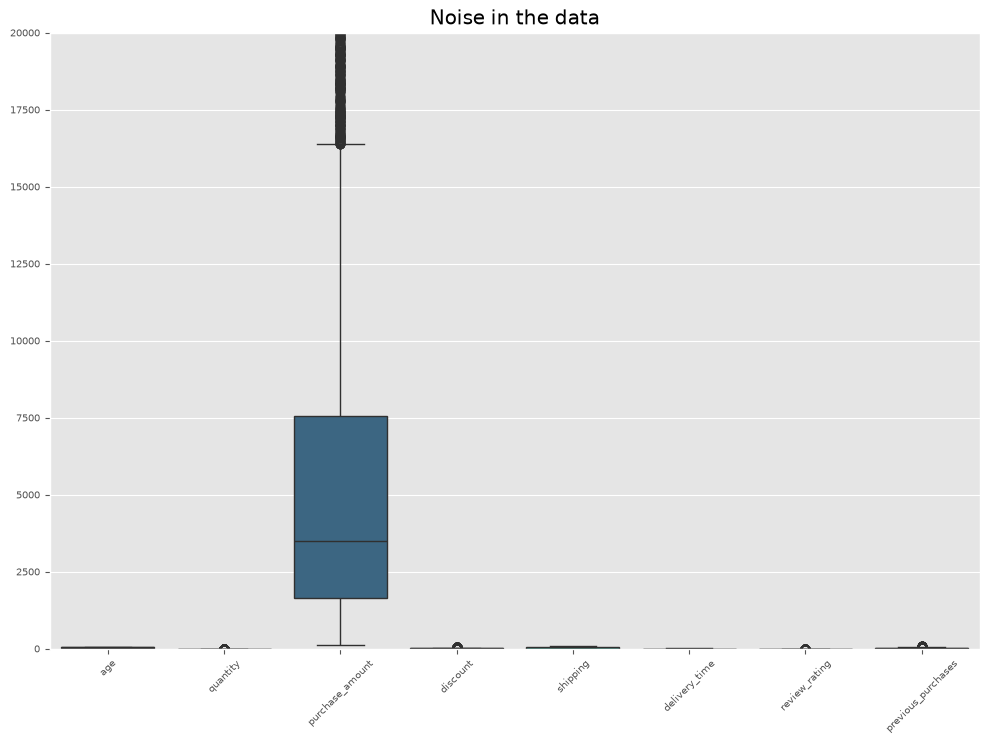

In [82]:
# Data quality & noise analysis
print(f"The dataset has : {df.isna().sum().sum()} null values")

# Count orders with zero or negative quantity
print(f"Orders with zero or negative quantity : {(df['quantity'] <= 0).sum()}")

# Outliers overview via Boxplot
plt.figure(figsize=[12,8])
plt.style.use('ggplot')
plt.title("Noise in the data")
sns.boxplot(df,palette='viridis')
plt.xticks(rotation=45,fontsize=7)
plt.yticks(fontsize=7)
plt.ylim(0, 20000)
plt.show()


## Outlier Audit
We'll use the IQR method to identify and calculate the percentage of outliers present in the important numerical features.

Feature age has 0.0% Outliers
Feature quantity has 2.06% Outliers
Feature purchase_amount has 9.29% Outliers
Feature discount has 4.21% Outliers
Feature shipping has 0.0% Outliers
Feature delivery_time has 0.0% Outliers
Feature review_rating has 1.02% Outliers
Feature previous_purchases has 2.94% Outliers


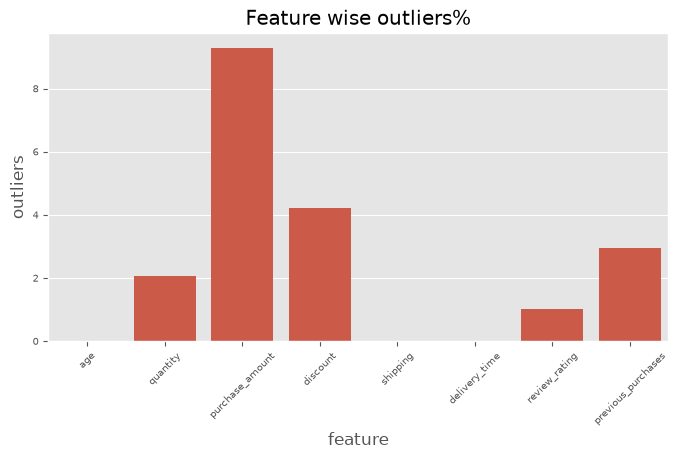

In [83]:
# Outliers audit
dummy = []
for i in df.select_dtypes(include=[int]):
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - (1.5*iqr)
    upper = q3 + (1.5*iqr)
    print(f"Feature {i} has {((df[i]<lower)|(df[i]>upper)).sum()/len(df[i])*100}% Outliers")
    dummy.append({"feature":i,"outliers":((df[i]<lower)|(df[i]>upper)).sum()/len(df[i])*100})
outlier_df = pd.DataFrame(dummy)

# Visualization
plt.figure(figsize=[8,4])
plt.style.use('ggplot')
plt.title("Feature wise outliers%",color='black')
sns.barplot(x=outlier_df['feature'],y=outlier_df['outliers'])
plt.xticks(rotation=45,fontsize=7)
plt.yticks(fontsize=7)
plt.show()


### Duplicate Audit
We'll check for duplicate transaction IDs to ensure that the dataset does not contain repeated transactions.

In [84]:
# Duplicate values column-wise
df['transaction_id'].duplicated().sum()

np.int64(0)

# DATA QUALITY
> - Dataset has no duplicate rows and no duplicate transaction IDs
> - Null value count is also zero
> - All important numerical features are in workable numerical formats; transaction_id & customer_id will be handled separately
> - Several numerical features have outliers
> - review_rating shows 1.02% outliers, but these are 1-star ratings, which are genuine customer feedback, not errors, so we keep them
> - purchase_amount has 9.29% outliers & discount has 4.21% outliers
> - We'll not drop these outliers as they may represent genuine customer behavior or normal variations, such as higher purchase amounts and discounts during sale/festival events

In [85]:
# Removing the "TXN" and "CUST" text from the IDs and keep only the numbers 

df['transaction_id'] = df['transaction_id'].str.removeprefix('TXN').astype(int)
df['customer_id'] = df['customer_id'].str.removeprefix('CUST').astype(int)

df[['transaction_id', 'customer_id']].head(3)    

,transaction_id,customer_id
0,500000,1440
1,500001,2326
2,500002,2680


## Data Consistency Checks
Checking that the data follows real-world business rules.

In [86]:
# Offline orders should have no shipping charge and no delivery time
offline_shipping_charges = df[df['online/offline']=='Offline']['shipping'].unique()
offline_delivery_times = df[df['online/offline']=='Offline']['delivery_time'].unique()
print(f"Unique shipping charges in offline purchases: {offline_shipping_charges}")
print(f"Unique delivery times in offline purchases :{offline_delivery_times}")
if offline_delivery_times|offline_shipping_charges:
    status = 'Fail'
else:
    status = 'Pass'
print(f"Data consistency check : {status}")


Unique shipping charges in offline purchases: [0]
Unique delivery times in offline purchases :[0]
Data consistency check : Pass


In [87]:
# In-Store purchases should only be offline
errors = (df[df['online_store']=='In-Store Purchase']['online/offline'] == 'Online').sum()
print(f"Errors in online/offline labelling : {errors}")
if errors:
    status = 'Fail'
else:
    status = 'Pass'
print(f"Data consistency check : {status}")

Errors in online/offline labelling : 0
Data consistency check : Pass


### Delivery Speed vs Delivery Time
> As per the dataset description, Standard delivery takes 3–7 days and Express delivery takes 1–2 days. We check whether the data follows this rule.

In [88]:
# Number of orders for each delivery speed and delivery time
delivery_matrix = pd.crosstab(df['delivery_speed'],df['delivery_time'])
delivery_matrix

delivery_time,0,1,2,3,4,5,6,7
delivery_speed,,,,,,,,
Express,0,1102,1065,0,0,0,0,0
N/A (Offline),2583,0,0,0,0,0,0,0
Same Day,729,0,0,0,0,0,0,0
Standard,0,0,0,952,904,824,906,935


### Festival / Sale vs Online Store
> Platform-specific sales (e.g. Big Billion Days is Flipkart's sale) should only appear on their own platform, and in-store offers only in physical stores.

In [89]:
# Number of orders for each sale on each store
store_sale_crosstab = pd.crosstab(df['festival/sale'], df['online_store'])
store_sale_crosstab

online_store,Ajio,Amazon,Flipkart,In-Store Purchase,Meesho,Myntra,Nykaa
festival/sale,,,,,,,
Amazon Great Indian Festival,0,16,0,0,0,0,0
Big Billion Days,0,0,19,0,0,0,0
Diwali Sale,33,27,13,0,18,14,19
In-Store Festival Offer,0,0,0,878,0,0,0
Independence Day Sale,15,13,12,0,10,7,5
Myntra End of Reason Sale,0,0,0,0,0,16,0
Nykaa Pink Friday,0,0,0,0,0,0,10
Republic Day Sale,6,2,7,0,5,11,9
Standard Day,1222,1171,1161,1705,1244,1170,1162


### Payment Method vs Channel
> Cash on Delivery is only possible online, while cash is paid directly only in physical stores.

In [90]:
# Number of orders for each payment method in each channel
payment_channel_matrix = pd.crosstab(df['online/offline'], df['payment_method'])
payment_channel_matrix

payment_method,Cash,Cash on Delivery,Credit Card,Debit Card,Net Banking,UPI,Wallet
online/offline,,,,,,,
Offline,535,0,527,257,0,1264,0
Online,0,1091,1448,1163,355,3015,345


In [91]:
# Smallest and largest value of each numeric column
min_max_tab = df.select_dtypes(include=int).agg(['min', 'max'])
min_max_tab

,transaction_id,customer_id,age,quantity,purchase_amount,discount,shipping,delivery_time,review_rating,previous_purchases
min,500000,1,18,1,107,0,0,0,1,0
max,509999,3500,64,4,113920,69,99,7,5,85


In [92]:
# Each item should belong to only one category
errors = df.groupby('item_purchased')['category'].nunique().max()
if errors == 1:
    status = 'Pass'
else:
    status = 'fail'

print(f"Data consistency check : {status}")

Data consistency check : Pass


In [93]:
# Sizes available in each category
category_size_tab = pd.crosstab(df['category'], df['size'])
category_size_tab

size,10,11,6,7,8,9,Free Size,L,M,S,XL,XS,XXL
category,,,,,,,,,,,,,
Accessories,0,0,0,0,0,0,1262,62,206,71,0,0,0
Clothing,0,0,0,0,0,0,0,837,794,794,865,877,837
Footwear,603,565,576,537,538,576,0,0,0,0,0,0,0


### Customer Profile Consistency
> Age, gender, location, subscription and purchase frequency are customer profile details, so each customer should have only one value for each across all their transactions.

In [94]:
# Number of different values per customer
errors = df.groupby('customer_id')[['age','gender','location','subscription_status',
                        'frequency_of_purchases']].nunique().max()
if errors.max() == 1:
    status = 'Pass'
else:
    status = 'fail'

print(f"Data consistency check : {status}")


Data consistency check : Pass


### Subscription vs Shipping Charge
> According to the dataset description, premium subscribers often receive no shipping charges. We check how many subscribers actually paid for shipping.

In [95]:
# Number of Subscribers paid for shipping
errors = (df[df['subscription_status']=='Yes']['shipping']>0).sum()
print(f"{errors} Subscriber orders paid for shipping")
if errors:
    status = "Fail"
else:
    status = "Pass"
print(f"Data consistency check : {status}")

99 Subscriber orders paid for shipping
Data consistency check : Fail


# DATA CONSISTENCY
> - All offline orders have 0 shipping & 0 delivery_time, which is correct for in-store purchases
> - In-Store Purchase is always labelled Offline & no offline order has an online store
> - delivery_time matches delivery_speed as per the dataset description; Standard takes 3–7 days & Express takes 1–2 days, while Same Day & offline orders have 0 days
> - Platform-specific sales appear only on their own platform, e.g. Big Billion Days only on Flipkart & In-Store Festival Offer only in physical stores
> - Payment methods fit their channel; Cash on Delivery appears only online & Cash only offline
> - All numerical features are in realistic ranges; age is 18–64, quantity 1–4, discount 0–69%, review_rating 1–5 & purchase_amount ₹107–₹1,13,920
> - Every item belongs to only one category & sizes match their category; clothing uses XS–XXL, footwear uses 6–11 & accessories are mostly Free Size
> - Each customer has only one age, gender, location, subscription_status & frequency_of_purchases across all transactions
> - 99 subscriber orders paid for shipping
> - All consistency checks pass except subscriber shipping, which is marked as Fail for now; we'll review it again later if needed

# FORECASTING OBJECTIVE & SCOPE

> - This section summarizes the overall purchasing activity using total units, unique transactions, and unique customers.
> - It compares online and offline purchases across units, transactions, and customers.
> - It examines category-level demand using units and transactions for both the complete dataset and the online-only data.
> - These comparisons help define a suitable target, sales channel, and category level for future forecasting.


In [96]:
# Comparing total units, transactions & customers.
target_summary = pd.DataFrame([{
    "units": df["quantity"].sum(),
    "transactions": df["transaction_id"].nunique(),
    "customers": df["customer_id"].nunique()
}])

target_summary

,units,transactions,customers
0,14259,10000,3291


In [97]:
# Comparing online & offline purchases.
channel_summary = df.groupby("online/offline").agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique"),
    customers=("customer_id", "nunique"))

channel_summary

,units,transactions,customers
online/offline,,,
Offline,3685,2583,1800
Online,10574,7417,3086


In [98]:
# Comparing category totals for both possible channel choices.
combined_category_summary = df.groupby("category").agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique"))

online_category_summary = df.loc[
    df["online/offline"] == "Online"
].groupby("category").agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique"))

print("ONLINE & OFFLINE TOGETHER")
display(combined_category_summary)

print("ONLINE ONLY")
display(online_category_summary)

ONLINE & OFFLINE TOGETHER


,units,transactions
category,,
Accessories,2294,1601
Clothing,7104,5004
Footwear,4861,3395


ONLINE ONLY


,units,transactions
category,,
Accessories,1726,1208
Clothing,5287,3728
Footwear,3561,2481


## FORECASTING SUMMARY

> - Around 74% of the purchased units come from online orders.
> - Clothing has the highest purchased quantity, while Accessories has the lowest, in both online-only & combined data.

# ANALYSIS PREPARATION

> - We'll Create a working copy & add simple columns for analysis.
> - Outline time periods for later forecasting decisions.
> - These helper columns are not automatically model features.

In [99]:
# Creating a date-sorted analysis copy
eda_df = df.copy()
eda_df = eda_df.sort_values("purchase_date", kind="stable").reset_index(drop=True)
eda_df.head(3)

,transaction_id,customer_id,purchase_date,age,gender,location,online/offline,online_store,category,item_purchased,...,festival/sale,shipping,delivery_speed,delivery_time,subscription_status,payment_method,review_rating,return_status,previous_purchases,frequency_of_purchases
0,500407,215,2023-01-01,46,Male,Visakhapatnam,Online,Ajio,Accessories,Belt,...,Standard Day,0,Standard,7,Yes,Debit Card,3,Not Returned,22,Fortnightly
1,503164,2409,2023-01-01,41,Male,Kochi,Offline,In-Store Purchase,Accessories,Socks,...,In-Store Festival Offer,0,N/A (Offline),0,Yes,Credit Card,2,Returned,0,Rarely
2,504311,2605,2023-01-01,47,Female,Visakhapatnam,Online,Amazon,Footwear,Slippers,...,Standard Day,60,Standard,5,No,UPI,4,Not Returned,57,Weekly


In [100]:
# Adding a small set of calendar helpers from purchase_date & flagging sale events/festivals.
eda_df["year"] = eda_df["purchase_date"].dt.year
eda_df["month"] = eda_df["purchase_date"].dt.month
eda_df["weekday"] = eda_df["purchase_date"].dt.day_name()
eda_df["is_weekend"] = eda_df["purchase_date"].dt.dayofweek >= 5
eda_df["is_sale"] = eda_df["festival/sale"] != "Standard Day"

eda_df[['purchase_date','year','month','weekday','is_weekend','is_sale']].head(3)

,purchase_date,year,month,weekday,is_weekend,is_sale
0,2023-01-01,2023,1,Sunday,True,False
1,2023-01-01,2023,1,Sunday,True,True
2,2023-01-01,2023,1,Sunday,True,False


In [101]:
# Summarizing the sale potential of different festival events
event_sale_summary = (
    eda_df.groupby(["festival/sale", "is_sale"])
    .size()
    .reset_index(name="transactions")
)

standard_discount_count = (
    (eda_df["festival/sale"] == "Standard Day")
    & (eda_df["discount"] > 0)
).sum()

event_discount_count = (
    (eda_df["festival/sale"] != "Standard Day")
    & (eda_df["discount"] > 0)
).sum()

display(event_sale_summary)
print(f"Standard Day transactions with a discount: {standard_discount_count}")
print(f"Event Day transactions with a discount: {event_discount_count}")
print(f"Total Events count : {(eda_df["festival/sale"] != "Standard Day").sum()}")

,festival/sale,is_sale,transactions
0,Amazon Great Indian Festival,True,16
1,Big Billion Days,True,19
2,Diwali Sale,True,124
3,In-Store Festival Offer,True,878
4,Independence Day Sale,True,62
5,Myntra End of Reason Sale,True,16
6,Nykaa Pink Friday,True,10
7,Republic Day Sale,True,40
8,Standard Day,False,8835


Standard Day transactions with a discount: 8202
Event Day transactions with a discount: 1165
Total Events count : 1165


In [102]:
# Calculating recorded amount per unit.
eda_df["amount_per_unit"] = (eda_df["purchase_amount"] / eda_df["quantity"])

display(eda_df[["purchase_amount", "quantity", "amount_per_unit"]].head().round(2))

# Checking any errors in recorded transaction amounts or unit quantities.
if (eda_df['purchase_amount']>0).all():
    print("All purchases are positive - No errors")
else:
    print("Some purchases are 0 or negative")
if (eda_df['quantity']>0).all():
    print("No errors in unit quantities recorded")
else:
    print("Errors in unit quantities recorded")

,purchase_amount,quantity,amount_per_unit
0,4750,2,2375.00
1,1350,3,450.00
2,1087,1,1087.00
3,500,1,500.00
4,4705,3,1568.33


All purchases are positive - No errors
No errors in unit quantities recorded


### KEY OBSERVATIONS

> - 1,165 transactions have a sale/festival label, while 8,835 are marked Standard Day.
> - All sale/festival transactions have discounts, but 8,202 Standard Day transactions also have discounts. Therefore, is_sale uses the event label, not the discount.
> - All recorded purchase_amount & quantity values are positive.
> - amount_per_unit represents the recorded purchase amount divided by quantity; it is not a verified list price or profit.

# UNIVARIATE NUMERICAL ANALYSIS

> - We'll check the typical values, spread & distribution of numerical columns, one at a time.
> - Age will be checked once per customer, while shipping & delivery time will use online transactions.

In [103]:
# Comparing the mean, median & spread of numerical columns.
numeric_summary = df.select_dtypes(include=int).describe()
numeric_summary.round(2)

,transaction_id,customer_id,age,quantity,purchase_amount,discount,shipping,delivery_time,review_rating,previous_purchases
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,504999.50,1756.76,41.10,1.43,6467.69,8.70,20.47,2.58,3.48,14.68
std,2886.90,1016.71,13.54,0.73,8777.62,7.28,28.95,2.47,0.87,15.96
min,500000.00,1.00,18.00,1.00,107.00,0.00,0.00,0.00,1.00,0.00
25%,502499.75,871.00,29.00,1.00,1659.00,4.00,0.00,0.00,3.00,2.00
50%,504999.50,1754.50,41.00,1.00,3491.00,8.00,0.00,2.00,4.00,9.00
75%,507499.25,2633.25,53.00,2.00,7544.25,12.00,40.00,5.00,4.00,23.00
max,509999.00,3500.00,64.00,4.00,113920.00,69.00,99.00,7.00,5.00,85.00


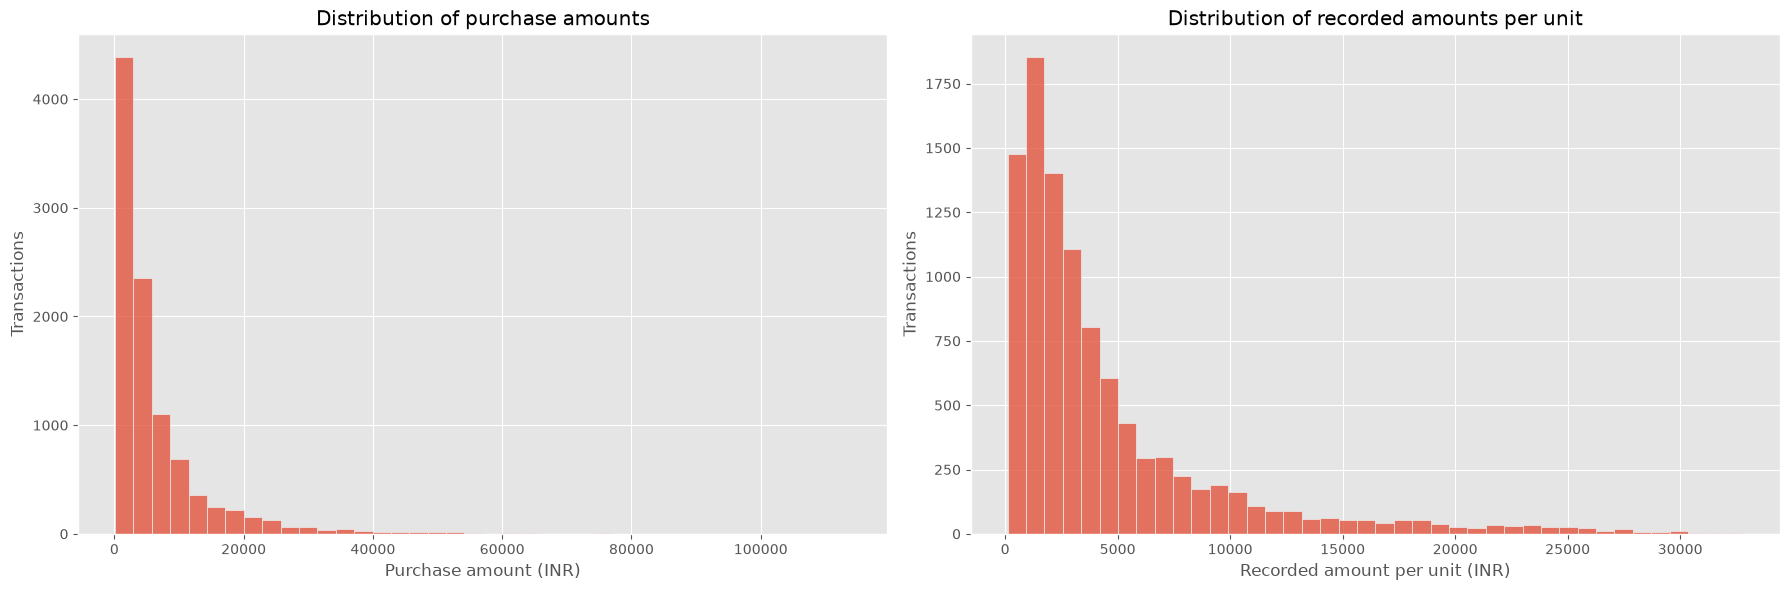

In [104]:
plt.figure(figsize=(18, 6))

# Checking the distribution of purchase amounts.
plt.subplot(1, 2, 1)
sns.histplot(data=eda_df, x="purchase_amount", bins=40)
plt.title("Distribution of purchase amounts")
plt.xlabel("Purchase amount (INR)")
plt.ylabel("Transactions")

# Checking the distribution of recorded amounts per unit.
plt.subplot(1, 2, 2)
sns.histplot(data=eda_df, x="amount_per_unit", bins=40)
plt.title("Distribution of recorded amounts per unit")
plt.xlabel("Recorded amount per unit (INR)")
plt.ylabel("Transactions")

plt.tight_layout()
plt.show()

In [105]:
# Counting online transactions for each shipping charge.
print("Transactions count for unique shipping charges")
display(pd.DataFrame(eda_df[eda_df["online/offline"]=='Online']['shipping'].value_counts().reset_index()))

# Counting transactions for each quantity, rating & delivery days.
count_summary = pd.DataFrame({
    "quantity": eda_df["quantity"].value_counts(),
    "review_rating": eda_df["review_rating"].value_counts(),
    "delivery_time":eda_df['delivery_time'].value_counts()
}).sort_index().fillna(0).astype(int)

print("Transactions count for unique quantities,rating & delivery time")
display(count_summary)

Transactions count for unique shipping charges


,shipping,count
0,0,3613
1,40,2219
2,60,1050
3,99,535


Transactions count for unique quantities,rating & delivery time


,quantity,review_rating,delivery_time
0,0,0,3312
1,6947,102,1102
2,2053,1181,1065
3,794,3613,952
4,206,4027,904
5,0,1077,824
6,0,0,906
7,0,0,935


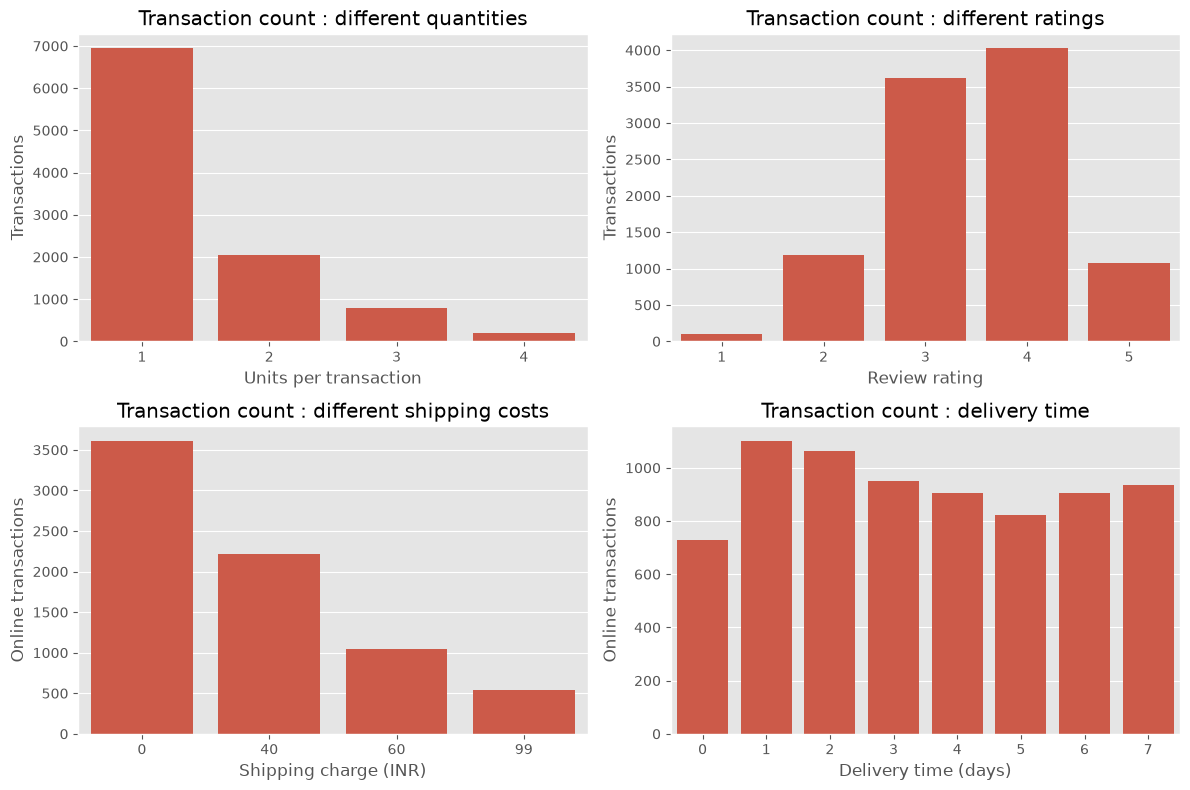

In [106]:
plt.figure(figsize=(12, 8))

# Checking the number of units in each transaction.
plt.subplot(2, 2, 1)
sns.countplot(data=eda_df, x="quantity")
plt.title("Transaction count : different quantities")
plt.xlabel("Units per transaction")
plt.ylabel("Transactions")

# Checking ratings recorded on transactions.
plt.subplot(2, 2, 2)
sns.countplot(data=eda_df, x="review_rating")
plt.title("Transaction count : different ratings")
plt.xlabel("Review rating")
plt.ylabel("Transactions")

# Checking shipping charges for online transactions.
online_numeric = eda_df.loc[eda_df["online/offline"] == "Online",["shipping", "delivery_time"]]
plt.subplot(2, 2, 3)
sns.countplot(data=online_numeric, x="shipping")
plt.title("Transaction count : different shipping costs")
plt.xlabel("Shipping charge (INR)")
plt.ylabel("Online transactions")

# Checking delivery time for online transactions.
plt.subplot(2, 2, 4)
sns.countplot(data=online_numeric, x="delivery_time")
plt.title("Transaction count : delivery time")
plt.xlabel("Delivery time (days)")
plt.ylabel("Online transactions")

plt.tight_layout()
plt.show()

Transactions with zero discount:633
Zero discount percentage:6.33


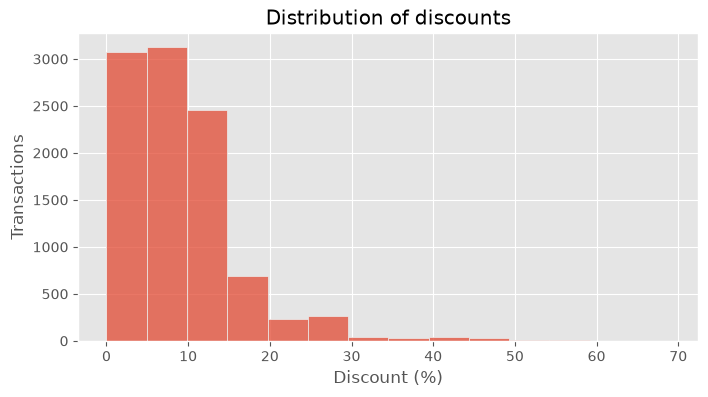

In [107]:
# Checking transactions with zero discount. 
zero_discount = (eda_df["discount"] == 0).sum()
print(f"Transactions with zero discount:{zero_discount}")
print(f"Zero discount percentage:{round(zero_discount / len(eda_df) * 100, 2)}")

# Checking the distribution of discounts.
plt.figure(figsize=(8, 4))
sns.histplot(data=eda_df, x="discount", binwidth=5)
plt.title("Distribution of discounts")
plt.xlabel("Discount (%)")
plt.ylabel("Transactions")
plt.show()

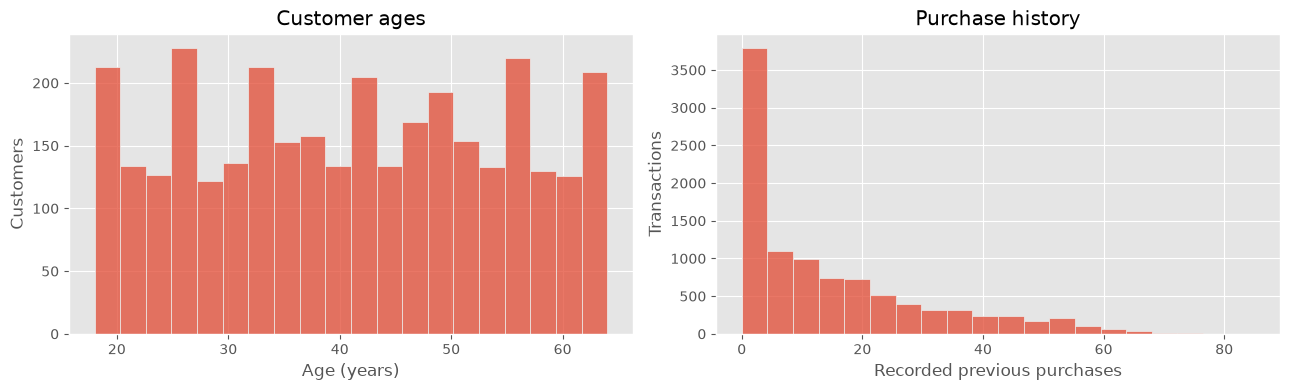

In [108]:
plt.figure(figsize=(13, 4))

# Checking age distribution of customers.
customer_age = eda_df.drop_duplicates("customer_id")["age"]
plt.subplot(1, 2, 1)
sns.histplot(x=customer_age, bins=20)
plt.title("Customer ages")
plt.xlabel("Age (years)")
plt.ylabel("Customers")

# Checking previous purchases recorded on each transaction.
plt.subplot(1, 2, 2)
sns.histplot(data=eda_df, x="previous_purchases",bins=20)
plt.title("Purchase history")
plt.xlabel("Recorded previous purchases")
plt.ylabel("Transactions")

plt.tight_layout()
plt.show()

### UNIVARIATE NUMERICAL OBSERVATIONS

> - purchase_amount & amount_per_unit are right-skewed. Most values are towards the lower end, while a few large values create a long right tail. The mean purchase amount is ₹6,467.69, compared with a median of ₹3,491.
> - 6,947 transactions contain one unit, which is 69.47% of all transactions. Transactions with larger quantities are less common.
> - Ratings of 4 & 3 are the most common, while 1-star ratings are the least common.
> - Among 7,417 online transactions, 3,613 have zero shipping charges. ₹40 is the most common paid shipping charge.
> - Online delivery times range from 0 to 7 days. One-day delivery is the most common, while 0 days represents Same Day delivery.
> - Most discounts are below 15%, with a few much larger discounts. 633 transactions have zero discount, making up 6.33% of all transactions.
> - Customer ages range from 18 to 64 years, with customers spread across this range.
> - previous_purchases is right-skewed. Lower recorded values are more common, while a few transactions have much higher values. Its median is 9, compared with a mean of 14.68.

# UNIVARIATE CATEGORICAL ANALYSIS

> - We'll count categories to see which groups are common or rare & how much data each contains.
> - Customer profiles will use one row per customer; online stores & delivery speeds will use online transactions.
> - Product, channel, payment, return, festival, color & size counts will represent transactions.

In [109]:
# Preparing customer profile & online transactions.
customer_profile = eda_df.drop_duplicates("customer_id")
online_transactions = eda_df[eda_df["online/offline"] == "Online"]

print("All transactions:", len(eda_df))
print("Unique customers:", len(customer_profile))
print("Online transactions:", len(online_transactions))


All transactions: 10000
Unique customers: 3291
Online transactions: 7417


In [110]:
# Checking each category's share in total transactions.
category_counts = combined_category_summary[["transactions"]].copy().reset_index()
category_counts["transaction_pct"] = (category_counts["transactions"] / len(eda_df) * 100).round(2)
display(category_counts)

# Counting transactions for all items.
item_counts = eda_df["item_purchased"].value_counts().to_frame("transactions").reset_index()
item_counts["transaction_pct"] = (item_counts["transactions"] / len(eda_df) * 100).round(2)
display(item_counts)

,category,transactions,transaction_pct
0,Accessories,1601,16.01
1,Clothing,5004,50.04
2,Footwear,3395,33.95


,item_purchased,transactions,transaction_pct
0,Kurta,870,8.70
1,Running Shoes,861,8.61
2,Saree,846,8.46
3,Sneakers,817,8.17
4,Jacket,676,6.76
5,T-shirt,645,6.45
6,Shorts,604,6.04
7,Hoodie,417,4.17
8,Sandals,371,3.71
9,Heels,352,3.52


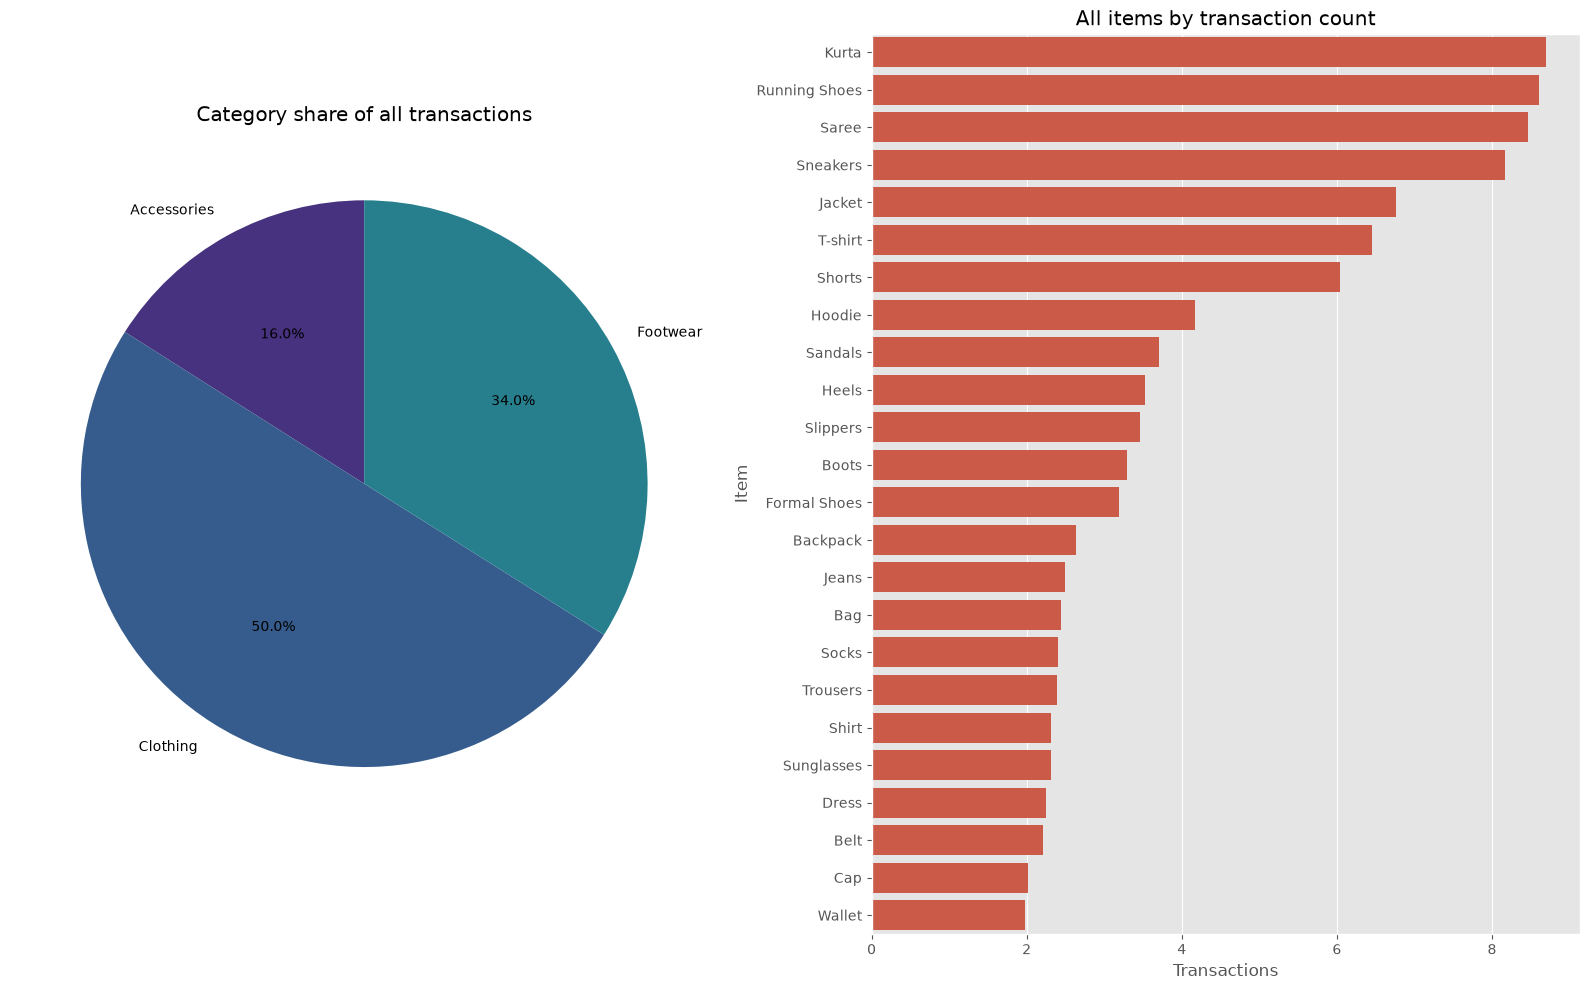

In [111]:
# Checking category shares & the most common items.
plt.figure(figsize=(16, 10))

plt.subplot(1, 2, 1)
plt.pie(category_counts["transactions"],labels=category_counts["category"],
    autopct="%1.1f%%",startangle=90,colors=sns.color_palette("viridis"))
plt.title("Category share of all transactions")

plt.subplot(1, 2, 2)
sns.barplot(data=item_counts,x="transaction_pct",y="item_purchased")
plt.title("All items by transaction count")
plt.xlabel("Transactions")
plt.ylabel("Item")

plt.tight_layout()
plt.show()

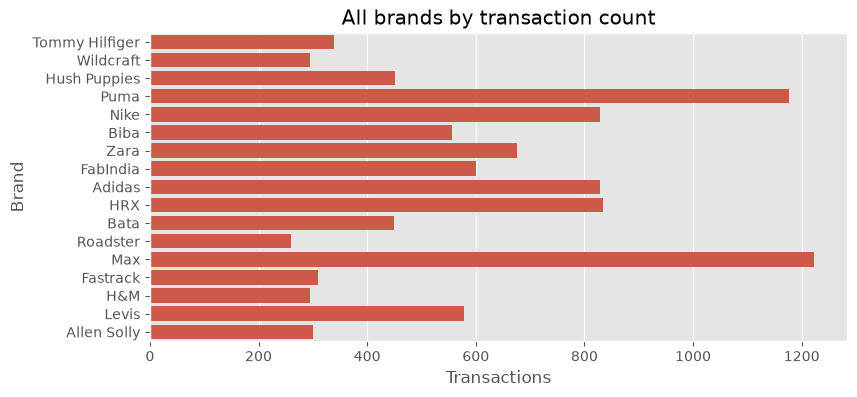

,brand,proportion
0,Max,12.23
1,Puma,11.77
2,HRX,8.35
3,Adidas,8.29
4,Nike,8.28
5,Zara,6.76
6,FabIndia,6.00
7,Levis,5.78
8,Biba,5.57
9,Hush Puppies,4.51


In [112]:
# Counting transactions for each brand.
brand_counts = eda_df["brand"].value_counts(normalize=True)*100

plt.figure(figsize=(9, 4))
sns.countplot(data=eda_df,y="brand",)
plt.title("All brands by transaction count")
plt.xlabel("Transactions")
plt.ylabel("Brand")
plt.show()

display(pd.DataFrame(brand_counts).reset_index())

,online_store,transactions,transaction_pct
0,Meesho,1277,17.22
1,Ajio,1276,17.20
2,Amazon,1229,16.57
3,Myntra,1218,16.42
4,Flipkart,1212,16.34
5,Nykaa,1205,16.25


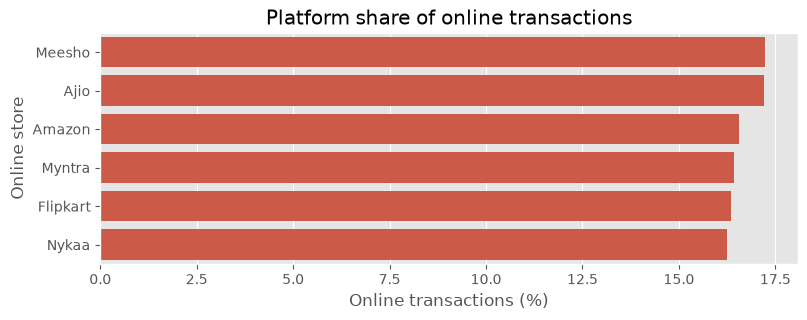

In [113]:
# Counting online transactions for each platform.
online_categorical = eda_df[eda_df["online/offline"] == "Online"]

store_counts = online_categorical["online_store"].value_counts().reset_index(name="transactions")
store_counts["transaction_pct"] = (
store_counts["transactions"] / len(online_categorical) * 100).round(2)

display(store_counts)

# Checking each platform's share of online transactions.
plt.figure(figsize=(9, 3))
sns.barplot(data=store_counts, x="transaction_pct", y="online_store")
plt.title("Platform share of online transactions")
plt.xlabel("Online transactions (%)")
plt.ylabel("Online store")
plt.show()

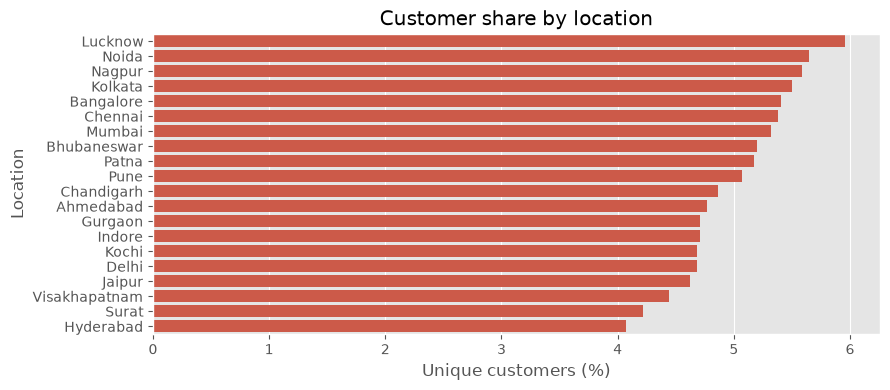

,location,customers,customer_pct
0,Lucknow,196,5.96
1,Noida,186,5.65
2,Nagpur,184,5.59
3,Kolkata,181,5.50
4,Bangalore,178,5.41
5,Chennai,177,5.38
6,Mumbai,175,5.32
7,Bhubaneswar,171,5.20
8,Patna,170,5.17
9,Pune,167,5.07


In [114]:
# Counting unique customers in each location.
location_counts = customer_profile["location"].value_counts().reset_index(name="customers")
location_counts["customer_pct"] = (location_counts["customers"] / len(customer_profile) * 100).round(2)

plt.figure(figsize=(9, 4))
sns.barplot(data=location_counts, x="customer_pct", y="location")
plt.title("Customer share by location")
plt.xlabel("Unique customers (%)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

display(location_counts)

,gender,customers,customer_pct
0,Female,1601,48.65
1,Male,1576,47.89
2,Other,114,3.46


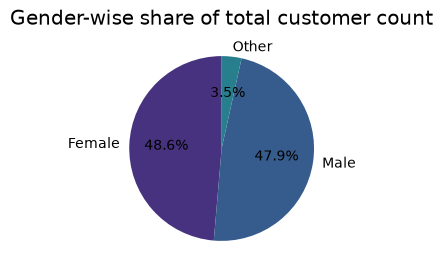

In [115]:
# Counting unique customers for each gender label.
gender_counts = customer_profile["gender"].value_counts().reset_index(name="customers")
gender_counts["customer_pct"] = (gender_counts["customers"] / len(customer_profile) * 100).round(2)
display(gender_counts)

plt.figure(figsize=(3,3))
plt.pie(gender_counts["customers"],labels=gender_counts["gender"],
autopct="%1.1f%%",startangle=90,colors=sns.color_palette("viridis"))
plt.title("Gender-wise share of total customer count")
plt.show()

In [116]:
# Counting customers by subscription status.
subscription_counts = customer_profile["subscription_status"].value_counts().reset_index(name="customers")
subscription_counts["customer_pct"] = (
subscription_counts["customers"] / len(customer_profile) * 100).round(2)
display(subscription_counts)

# Counting customers in the frequency groups.
frequency_counts = customer_profile["frequency_of_purchases"].value_counts()
frequency_counts = frequency_counts.reset_index(name="customers")
frequency_counts["customer_pct"] = (
frequency_counts["customers"] / len(customer_profile) * 100).round(2)
display(frequency_counts)

,subscription_status,customers,customer_pct
0,No,2320,70.5
1,Yes,971,29.5


,frequency_of_purchases,customers,customer_pct
0,Rarely,700,21.27
1,Fortnightly,670,20.36
2,Weekly,659,20.02
3,Monthly,639,19.42
4,Quarterly,623,18.93


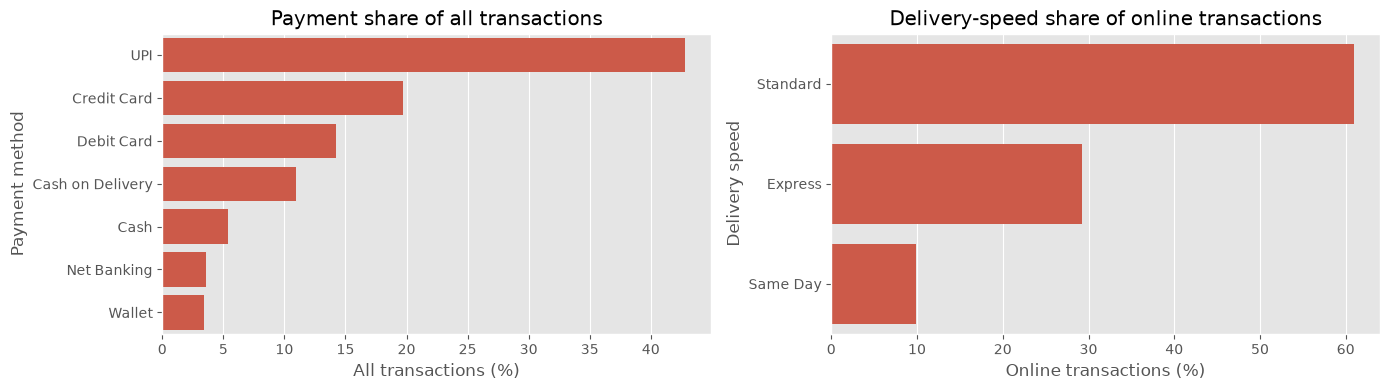

,payment_method,transactions,transaction_pct
0,UPI,4279,42.79
1,Credit Card,1975,19.75
2,Debit Card,1420,14.20
3,Cash on Delivery,1091,10.91
4,Cash,535,5.35
5,Net Banking,355,3.55
6,Wallet,345,3.45


,delivery_speed,transactions,transaction_pct
0,Standard,4521,60.95
1,Express,2167,29.22
2,Same Day,729,9.83


In [117]:
# Counting payment methods across all transactions.
payment_counts = eda_df["payment_method"].value_counts().reset_index(name="transactions")
payment_counts["transaction_pct"] = (
    payment_counts["transactions"] / len(eda_df) * 100).round(2)

# Counting delivery labels for online transactions.
delivery_counts = online_categorical["delivery_speed"].value_counts().reset_index(name="transactions")
delivery_counts["transaction_pct"] = (
    delivery_counts["transactions"] / len(online_categorical) * 100).round(2)

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.barplot(data=payment_counts, x="transaction_pct", y="payment_method")
plt.title("Payment share of all transactions")
plt.xlabel("All transactions (%)")
plt.ylabel("Payment method")

plt.subplot(1, 2, 2)
sns.barplot(data=delivery_counts, x="transaction_pct", y="delivery_speed")
plt.title("Delivery-speed share of online transactions")
plt.xlabel("Online transactions (%)")
plt.ylabel("Delivery speed")

plt.tight_layout()
plt.show()

display(payment_counts)
display(delivery_counts)

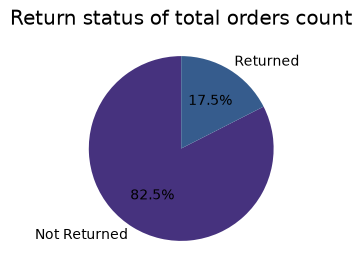

,return_status,transactions,transaction_pct
0,Not Returned,8249,82.49
1,Returned,1751,17.51


In [118]:
# Counting recorded return outcomes across all transactions.
return_counts = eda_df["return_status"].value_counts().reset_index(name="transactions")
return_counts["transaction_pct"] = (
return_counts["transactions"] / len(eda_df) * 100).round(2)

plt.figure(figsize=(3,3))
plt.pie(return_counts["transactions"],labels=return_counts["return_status"],
autopct="%1.1f%%",startangle=90,colors=sns.color_palette("viridis"))
plt.title("Return status of total orders count")
plt.show()

display(return_counts)

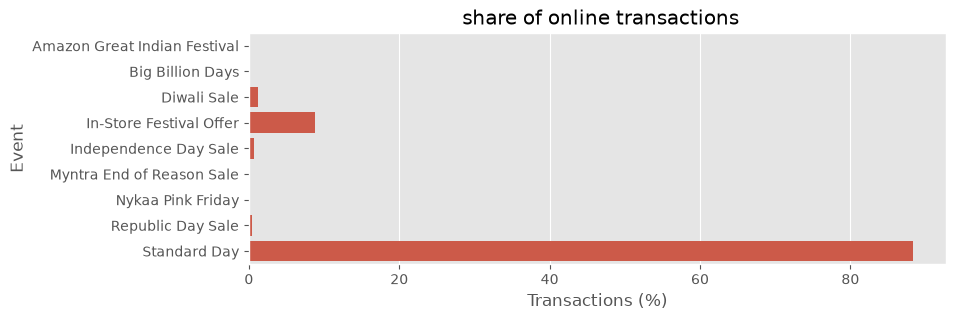

,festival/sale,transactions,transaction_pct
0,Amazon Great Indian Festival,16,0.16
1,Big Billion Days,19,0.19
2,Diwali Sale,124,1.24
3,In-Store Festival Offer,878,8.78
4,Independence Day Sale,62,0.62
5,Myntra End of Reason Sale,16,0.16
6,Nykaa Pink Friday,10,0.10
7,Republic Day Sale,40,0.40
8,Standard Day,8835,88.35


In [119]:
# Checking festival-label shares using the existing counts.
festival_counts = event_sale_summary[["festival/sale", "transactions"]].copy()
festival_counts["transaction_pct"] = (festival_counts["transactions"] / len(eda_df)*100).round(2)

plt.figure(figsize=[9,3])
sns.barplot(data=festival_counts, x="transaction_pct", y="festival/sale")
plt.title(" share of online transactions")
plt.xlabel("Transactions (%)")
plt.ylabel("Event")
plt.show()

display(festival_counts)

In [120]:
# Counting recorded colors across all transactions.
color_counts = eda_df["color"].value_counts().reset_index(name="transactions")
color_counts["transaction_pct"] = (color_counts["transactions"] / len(eda_df) * 100).round(2)
display(color_counts)

,color,transactions,transaction_pct
0,Grey,1078,10.78
1,Beige,1022,10.22
2,Navy,1010,10.10
3,Red,1004,10.04
4,Blue,1004,10.04
5,Black,997,9.97
6,Green,980,9.80
7,Olive,974,9.74
8,White,972,9.72
9,Brown,959,9.59


### UNIVARIATE CATEGORICAL SUMMARY

> - The analysis covers 10,000 transactions & 3,291 unique customers. Customer-profile percentages use unique customers, while online-store & delivery-speed percentages use the 7,417 online transactions.
> - Clothing accounts for the largest share of transactions at 50.04%, followed by Footwear at 33.95% & Accessories at 16.01%.
> - Kurta, Running Shoes & Saree are the most frequently recorded items, accounting for 8.70%, 8.61% & 8.46% of transactions. Wallet has the smallest share at 1.98%.
> - Max & Puma have the largest brand shares at 12.23% & 11.77% of transactions. Roadster has the smallest share at 2.59%.
> - Online transactions are spread fairly evenly across the six platforms. Meesho & Ajio have the largest shares at 17.22% & 17.20%, while Nykaa has the smallest at 16.25%.
> - Customers are spread across 20 locations, with each location representing roughly 4–6% of unique customers. Lucknow has the largest share at 5.96%, while Hyderabad has the smallest at 4.07%.
> - Female & Male customers have similar representation at 48.65% & 47.89%. Customers with the Other gender label account for 3.46%.
> - Most customers are not subscribers: 70.50% have subscription_status marked No, compared with 29.50% marked Yes.
> - The purchase-frequency groups are fairly evenly represented. Rarely is the largest group at 21.27% of customers & Quarterly is the smallest at 18.93%. These labels are not calculated from the observed gaps between purchases.
> - UPI is the most common payment method, appearing in 42.79% of all transactions, followed by Credit Card at 19.75%. Wallet has the smallest share at 3.45%.
> - Standard delivery accounts for 60.95% of online transactions, followed by Express at 29.22% & Same Day at 9.83%.
> - 1,751 transactions are marked Returned, representing 17.51% of all transactions. The remaining 82.49% are marked Not Returned.
> - Standard Day accounts for 88.35% of transactions. In-Store Festival Offer is the largest named sale group at 8.78%, followed by Diwali Sale at 1.24%. Some labels have very little data; Nykaa Pink Friday has only 10 transactions, or 0.10%. These are transaction counts, not numbers of festival days.
> - Color shares are close, ranging from 9.59% to 10.78% of transactions. Grey has the largest share & Brown the smallest, with no single color accounting for a large proportion of purchases.

# BIVARIATE ANALYSIS

> - We'll compare two variables at a time to understand how purchase amounts, quantities, discounts, returns & ratings differ across groups.
> - We'll keep group sizes visible, compare typical values & use return percentages within each category.
> - Delivery comparisons will use online transactions.

,category,transactions,median_amount,mean_amount,mean_quantity
0,Accessories,1601,2102.0,3376.05,1.43
1,Clothing,5004,3035.5,4358.40,1.42
2,Footwear,3395,6719.0,11034.60,1.43


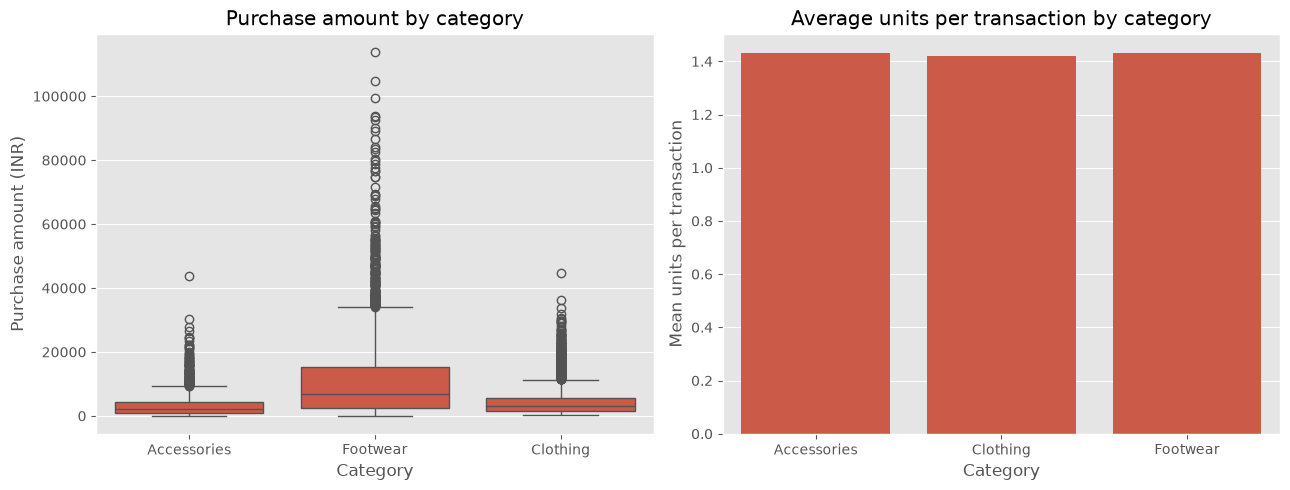

In [121]:
# Comparing purchase amounts & units per transaction across categories.
category_bivariate = eda_df.groupby("category").agg(
    transactions=("transaction_id", "size"),
    median_amount=("purchase_amount", "median"),
    mean_amount=("purchase_amount", "mean"),
    mean_quantity=("quantity", "mean")).reset_index()

display(category_bivariate.round(2))

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=eda_df, x="category", y="purchase_amount",)
plt.title("Purchase amount by category")
plt.xlabel("Category")
plt.ylabel("Purchase amount (INR)")

plt.subplot(1, 2, 2)
sns.barplot(data=category_bivariate, x="category", y="mean_quantity",)
plt.title("Average units per transaction by category")
plt.xlabel("Category")
plt.ylabel("Mean units per transaction")

plt.tight_layout()
plt.show()

,quantity,transactions,median_amount,mean_amount
0,1,6947,2750.0,4497.86
1,2,2053,5448.0,9329.52
2,3,794,8300.5,13749.99
3,4,206,9585.0,16307.41


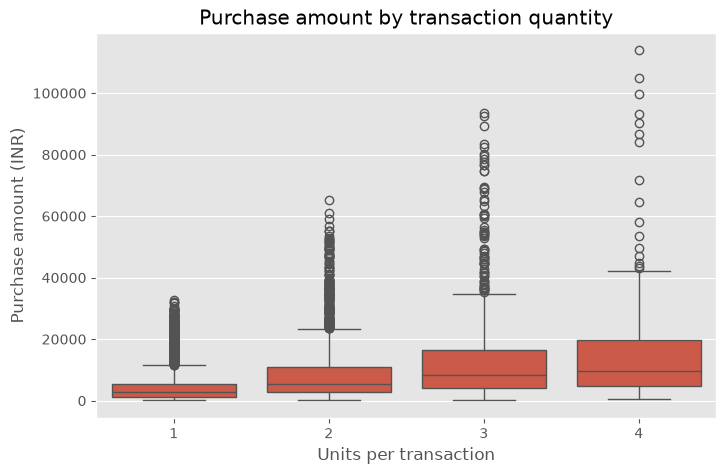

In [122]:
# Comparing purchase amounts for each transaction quantity.
quantity_amount = eda_df.groupby("quantity").agg(
    transactions=("transaction_id", "size"),
    median_amount=("purchase_amount", "median"),
    mean_amount=("purchase_amount", "mean")).reset_index()

display(quantity_amount.round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_df, x="quantity", y="purchase_amount",)
plt.title("Purchase amount by transaction quantity")
plt.xlabel("Units per transaction")
plt.ylabel("Purchase amount (INR)")
plt.show()

,festival/sale,transactions,median_discount,mean_discount
0,Amazon Great Indian Festival,16,39.5,39.62
1,Big Billion Days,19,43.0,41.58
2,Diwali Sale,124,32.0,32.89
3,In-Store Festival Offer,878,19.0,19.40
4,Independence Day Sale,62,24.5,24.34
5,Myntra End of Reason Sale,16,43.5,45.56
6,Nykaa Pink Friday,10,39.0,37.70
7,Republic Day Sale,40,25.5,25.12
8,Standard Day,8835,7.0,6.89


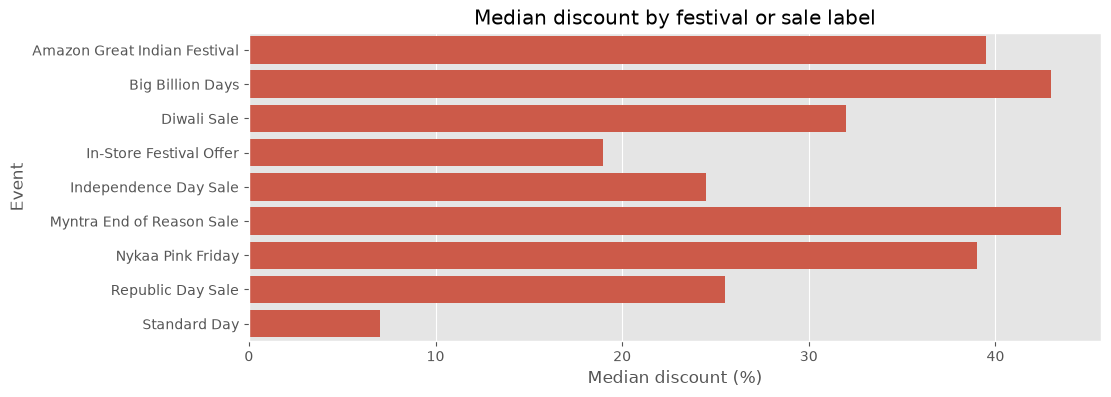

In [123]:
# Comparing recorded discounts across all festival & sale labels.
event_discount = eda_df.groupby("festival/sale").agg(
    transactions=("transaction_id", "size"),
    median_discount=("discount", "median"),
    mean_discount=("discount", "mean")).reset_index()

display(event_discount.round(2))

plt.figure(figsize=(11,4))
sns.barplot(data=event_discount, x="median_discount", y="festival/sale")
plt.title("Median discount by festival or sale label")
plt.xlabel("Median discount (%)")
plt.ylabel("Event")
plt.show()

,is_sale,transactions,mean_quantity,median_quantity
0,False,8835,1.43,1.0
1,True,1165,1.42,1.0


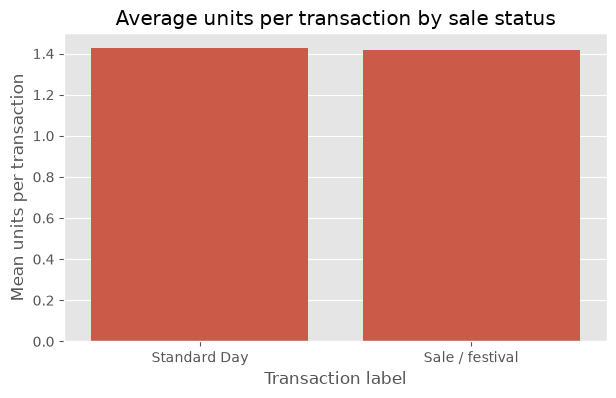

In [124]:
# Comparing units per transaction by the existing sale flag.
sale_quantity = eda_df.groupby("is_sale").agg(
    transactions=("transaction_id", "size"),
    mean_quantity=("quantity", "mean"),
    median_quantity=("quantity", "median")).reset_index()

display(sale_quantity.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(data=sale_quantity, x="is_sale", y="mean_quantity")
plt.xticks([False, True], ["Standard Day", "Sale / festival"])
plt.title("Average units per transaction by sale status")
plt.xlabel("Transaction label")
plt.ylabel("Mean units per transaction")
plt.show()

,online/offline,transactions,median_amount,mean_amount
0,Offline,2583,3572.0,6527.05
1,Online,7417,3476.0,6447.02


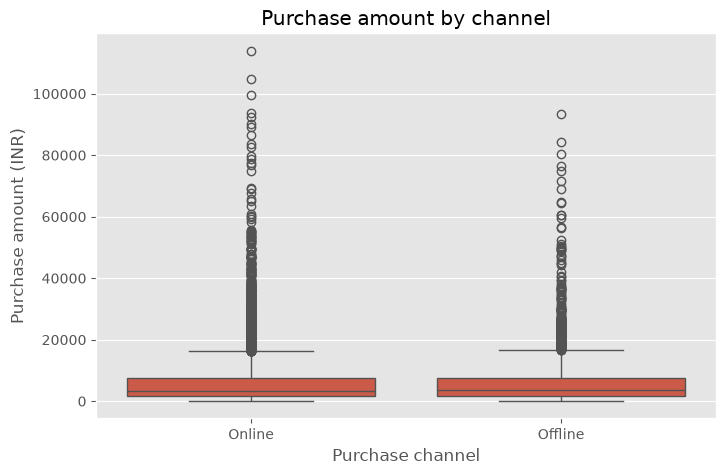

In [125]:
# Comparing purchase amounts across online & offline transactions.
channel_spending = eda_df.groupby("online/offline").agg(
    transactions=("transaction_id", "size"),
    median_amount=("purchase_amount", "median"),
    mean_amount=("purchase_amount", "mean")).reset_index()

display(channel_spending.round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_df, x="online/offline", y="purchase_amount")
plt.title("Purchase amount by channel")
plt.xlabel("Purchase channel")
plt.ylabel("Purchase amount (INR)")
plt.show()

return_status,category,Not Returned,Returned,transactions,return_rate_pct
0,Accessories,1439,162,1601,10.12
1,Clothing,4063,941,5004,18.80
2,Footwear,2747,648,3395,19.09


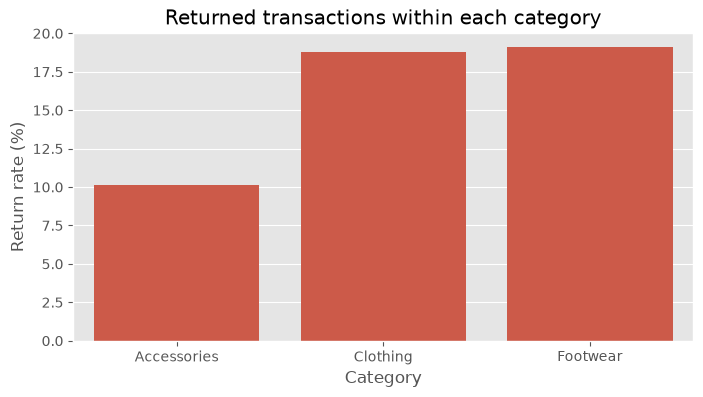

In [126]:
# Calculating the returned ratio within each category.
category_returns = pd.crosstab(eda_df["category"], eda_df["return_status"]).reset_index()
category_returns["transactions"] = (category_returns["Returned"] + category_returns["Not Returned"])
category_returns["return_rate_pct"] = (category_returns["Returned"] / category_returns["transactions"] * 100)

display(category_returns.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(data=category_returns, x="category", y="return_rate_pct")
plt.title("Returned transactions within each category")
plt.xlabel("Category")
plt.ylabel("Return rate (%)")
plt.show()

In [127]:
# Comparing review ratings across online delivery speeds.
delivery_ratings = online_transactions.groupby("delivery_speed").agg(
    transactions=("transaction_id", "size"),
    mean_rating=("review_rating", "mean"),
    median_rating=("review_rating", "median")).reset_index()

display(delivery_ratings.round(2))

delivery_rating_pct = pd.crosstab(online_transactions["delivery_speed"],
online_transactions["review_rating"],normalize="index") * 100

display(delivery_rating_pct.round(2))

,delivery_speed,transactions,mean_rating,median_rating
0,Express,2167,3.67,4.0
1,Same Day,729,3.66,4.0
2,Standard,4521,3.26,3.0


review_rating,1,2,3,4,5
delivery_speed,,,,,
Express,0.00,7.01,32.53,47.02,13.43
Same Day,0.00,6.45,33.33,48.29,11.93
Standard,2.26,17.92,39.62,32.16,8.05


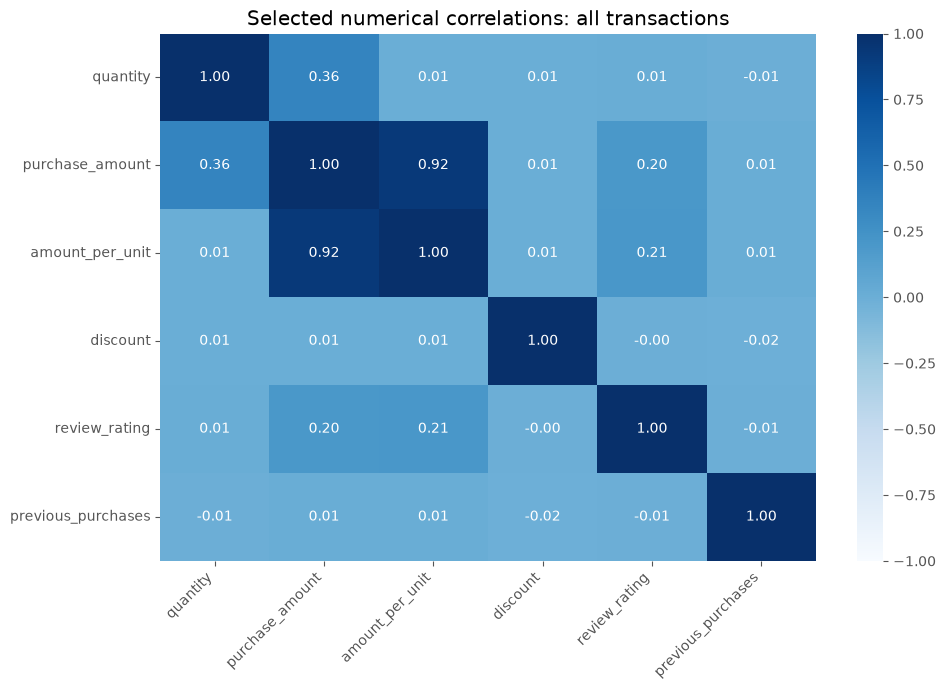

In [128]:
# Checking selected transaction-level relationships using Spearman correlation.
correlation_columns = ["quantity", "purchase_amount",
"amount_per_unit","discount", "review_rating", "previous_purchases"]
selected_correlations = eda_df[correlation_columns].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(selected_correlations, annot=True,cmap='Blues', fmt=".2f",vmin=-1,vmax=+1)
plt.title("Selected numerical correlations: all transactions")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### BIVARIATE SUMMARY

> - Footwear has the highest median purchase amount at ₹6,719, followed by Clothing at ₹3,035.50 & Accessories at ₹2,102. Average quantity is nearly identical across categories at around 1.42–1.43 units per transaction.
> - Median purchase amount increases with quantity, from ₹2,750 for one unit to ₹9,585 for four units. Quantity & purchase_amount have a positive Spearman correlation of 0.36.
> - Every sale/festival group has a higher median discount than Standard Day's 7%. Some event groups contain only 10–19 transactions, so their results should be interpreted cautiously.
> - Average quantity is almost the same for sale/festival transactions (1.42) & Standard Day transactions (1.43), with a median of one unit in both groups. This comparison does not measure changes in daily or weekly demand during promotions.
> - Typical purchase amounts are similar across channels: the median is ₹3,572 offline & ₹3,476 online. Mean amounts are also close.
> - Footwear has the highest within-category return rate at 19.09%, closely followed by Clothing at 18.80%; Accessories has a lower rate of 10.12%. Clothing has the most returned transactions, but not the highest return rate.
> - Among online transactions, Express & Same Day have similar average ratings of 3.67 & 3.66, compared with 3.26 for Standard delivery. Their median ratings are 4, compared with 3 for Standard delivery.
> - purchase_amount & amount_per_unit have a strong positive correlation of about 0.92, partly because amount_per_unit is calculated from purchase_amount divided by quantity.
> - Review ratings have weak positive correlations with purchase_amount (0.20) & amount_per_unit (0.21). Discount & previous_purchases show correlations close to zero with the other selected variables.
> - These findings describe transaction-level associations; they do not establish that one variable causes another to change.

# MULTIVARIATE ANALYSIS

> - This section compares quantity & purchase amount across category, sale status & purchase channel.
> - The aim is to see whether the patterns observed in the bivariate analysis are similar within each category.

,category,is_sale,transactions,mean_quantity,median_quantity,sale_status
0,Accessories,False,1427,1.44,1.0,Standard Day
1,Accessories,True,174,1.41,1.0,Sale/festival
2,Clothing,False,4435,1.42,1.0,Standard Day
3,Clothing,True,569,1.43,1.0,Sale/festival
4,Footwear,False,2973,1.44,1.0,Standard Day
5,Footwear,True,422,1.40,1.0,Sale/festival


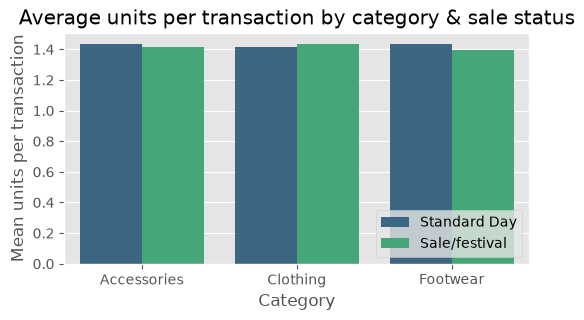

In [129]:
# Comparing sale & Standard Day quantities within each category.
sale_category_quantity = eda_df.groupby(["category", "is_sale"]).agg(
    transactions=("transaction_id", "size"),
    mean_quantity=("quantity", "mean"),
    median_quantity=("quantity", "median")).reset_index()

sale_category_quantity["sale_status"] = sale_category_quantity["is_sale"
].map({False: "Standard Day", True: "Sale/festival"})

display(sale_category_quantity.round(2))

plt.figure(figsize=(6, 3))
sns.barplot(data=sale_category_quantity,x="category", y="mean_quantity",
hue="sale_status",palette="viridis")
plt.title("Average units per transaction by category & sale status")
plt.xlabel("Category")
plt.ylabel("Mean units per transaction")
plt.legend(loc='lower right')
plt.show()

,category,online/offline,transactions,median_amount,mean_amount
0,Accessories,Offline,393,2071.0,3344.13
1,Accessories,Online,1208,2111.0,3386.44
2,Clothing,Offline,1276,2977.5,4339.50
3,Clothing,Online,3728,3054.5,4364.86
4,Footwear,Offline,914,6891.0,10949.59
5,Footwear,Online,2481,6630.0,11065.92


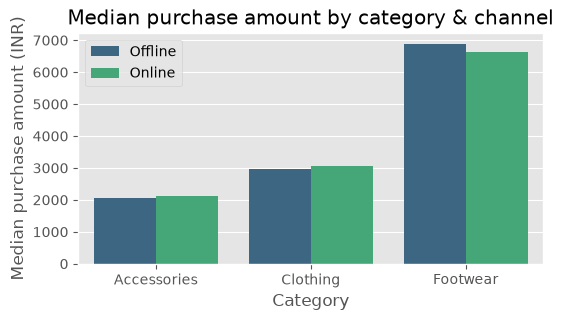

In [130]:
# Comparing online & offline purchase amounts within each category.
channel_category_amount = eda_df.groupby(["category", "online/offline"]).agg(
    transactions=("transaction_id", "size"),
    median_amount=("purchase_amount", "median"),
    mean_amount=("purchase_amount", "mean")).reset_index()

display(channel_category_amount.round(2))

plt.figure(figsize=(6, 3))
sns.barplot(data=channel_category_amount,x="category", y="median_amount",
hue="online/offline",palette="viridis")
plt.title("Median purchase amount by category & channel")
plt.xlabel("Category")
plt.ylabel("Median purchase amount (INR)")
plt.legend()
plt.show()

### MULTIVARIATE SUMMARY

> - Average quantity remains close between sale/festival & Standard Day transactions within all three categories. The median is one unit in every group.
> - Online & offline median purchase amounts are fairly similar within each category. Online medians are slightly higher for Accessories & Clothing, while Footwear has a slightly higher median offline.
> - Footwear has the highest typical purchase amount in both channels, followed by Clothing & Accessories. Differences between categories are more noticeable than differences between channels within a category.
> - The broad patterns from the bivariate analysis remain similar after grouping by category. These findings describe individual transactions & do not measure changes in daily or weekly demand.

# CUSTOMER PURCHASING CONTEXT

> - We'll look at how often customers purchased, how many units they bought & how much they spent during the period covered by the dataset.
> - We'll compare customer activity across subscription & purchase-frequency groups.

In [131]:
# Summarizing observed transactions, units & spending for each customer.
customer_summary = eda_df.groupby("customer_id").agg(
    observed_transactions=("transaction_id", "nunique"),
    observed_units=("quantity", "sum"),
    observed_spend=("purchase_amount", "sum"),
    subscription_status=("subscription_status", "first"),
    frequency_of_purchases=("frequency_of_purchases", "first")).reset_index()

print("Observed customers:", len(customer_summary))
print("Observed transactions:", customer_summary["observed_transactions"].sum())
print("Observed units:", customer_summary["observed_units"].sum())
print("Recorded spending (INR):", customer_summary["observed_spend"].sum())

Observed customers: 3291
Observed transactions: 10000
Observed units: 14259
Recorded spending (INR): 64676945


In [132]:
# Comparing single-transaction & multiple-transaction customers.
customer_summary["observed_purchase_group"] = (customer_summary["observed_transactions"] > 1
).map({False: "One observed transaction",True: "Multiple observed transactions"})

observed_purchase_groups = customer_summary.groupby("observed_purchase_group"
).agg(customers=("customer_id", "size")).reset_index()

observed_purchase_groups["customer_pct"] = (observed_purchase_groups["customers"] /
len(customer_summary) * 100)

display(observed_purchase_groups.round(2))

,observed_purchase_group,customers,customer_pct
0,Multiple observed transactions,2693,81.83
1,One observed transaction,598,18.17


,observed_transactions,customers,customer_pct
0,1,598,18.17
1,2,793,24.10
2,3,777,23.61
3,4,545,16.56
4,5,325,9.88
5,6,151,4.59
6,7,58,1.76
7,8,31,0.94
8,9,10,0.30
9,10,3,0.09


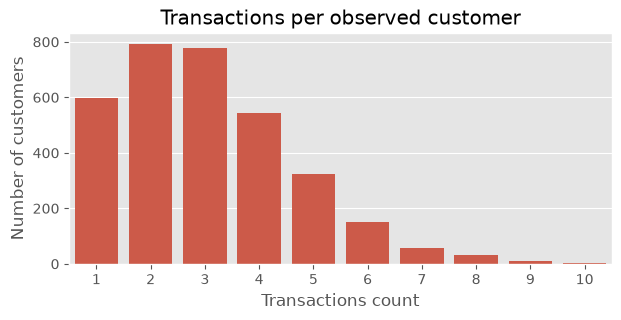

In [133]:
# Counting customers at each observed transaction count.
transaction_distribution = (customer_summary["observed_transactions"].value_counts()
.sort_index().reset_index(name="customers"))
transaction_distribution["customer_pct"] = (transaction_distribution["customers"]/
len(customer_summary) * 100)

display(transaction_distribution.round(2))

plt.figure(figsize=(7, 3))
sns.barplot(data=transaction_distribution,x="observed_transactions", y="customers")
plt.title("Transactions per observed customer")
plt.xlabel("Transactions count")
plt.ylabel("Number of customers")
plt.show()

,observed_transactions,observed_units,observed_spend
count,3291.00,3291.00,3291.00
mean,3.04,4.33,19652.67
std,1.62,2.63,18505.39
min,1.00,1.00,179.00
25%,2.00,2.00,6566.50
50%,3.00,4.00,14138.00
75%,4.00,6.00,26866.00
max,10.00,18.00,187570.00


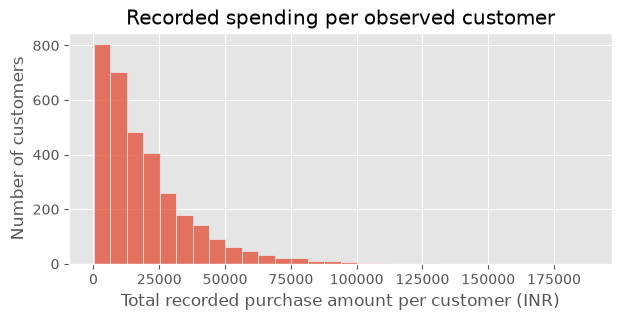

In [134]:
# Describing observed transactions, units & spending per customer.
customer_activity_stats = customer_summary[
["observed_transactions", "observed_units", "observed_spend"]].describe()

display(customer_activity_stats.round(2))

plt.figure(figsize=(7, 3))
sns.histplot(data=customer_summary,x="observed_spend", bins=30)
plt.title("Recorded spending per observed customer")
plt.xlabel("Total recorded purchase amount per customer (INR)")
plt.ylabel("Number of customers")
plt.show()

In [135]:
# Comparing observed customer activity by subscription status.
subscription_activity = customer_summary.groupby("subscription_status").agg(
    customers=("customer_id", "size"),
    mean_transactions=("observed_transactions", "mean"),
    median_transactions=("observed_transactions", "median"),
    median_units=("observed_units", "median"),
    median_spend=("observed_spend", "median"),
    mean_spend=("observed_spend", "mean")).reset_index()

display(subscription_activity.round(2))

,subscription_status,customers,mean_transactions,median_transactions,median_units,median_spend,mean_spend
0,No,2320,3.04,3.0,4.0,14130.5,19765.00
1,Yes,971,3.05,3.0,4.0,14205.0,19384.29


,frequency_of_purchases,customers,mean_transactions,median_transactions,median_units,median_spend,mean_spend
0,Fortnightly,670,2.99,3.0,4.0,14101.5,19769.19
1,Monthly,639,2.97,3.0,4.0,13581.0,19707.53
2,Quarterly,623,3.08,3.0,4.0,14709.0,19278.03
3,Rarely,700,3.06,3.0,4.0,14266.0,19795.65
4,Weekly,659,3.09,3.0,4.0,14319.0,19683.33


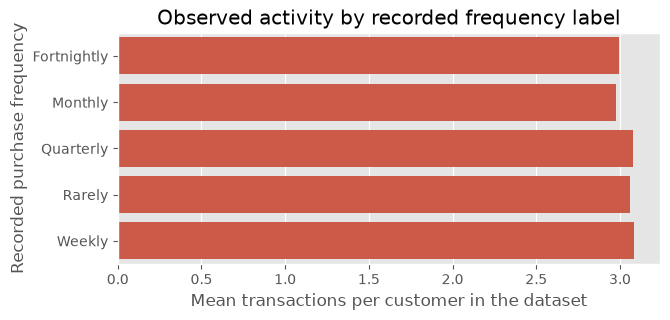

In [136]:
# Comparing observed customer activity across recorded frequency labels.
frequency_activity = customer_summary.groupby("frequency_of_purchases").agg(
    customers=("customer_id", "size"),
    mean_transactions=("observed_transactions", "mean"),
    median_transactions=("observed_transactions", "median"),
    median_units=("observed_units", "median"),
    median_spend=("observed_spend", "median"),
    mean_spend=("observed_spend", "mean")).reset_index()

display(frequency_activity.round(2))

plt.figure(figsize=(7, 3))
sns.barplot(data=frequency_activity,x="mean_transactions", y="frequency_of_purchases")
plt.title("Observed activity by recorded frequency label")
plt.xlabel("Mean transactions per customer in the dataset")
plt.ylabel("Recorded purchase frequency")
plt.show()

### CUSTOMER PURCHASING SUMMARY

> - Around 82% of customers have multiple transactions within the observed period. Two transactions is the most common count, while the median is three. These counts describe activity in this dataset, not lifetime purchase behaviour.
> - Median customer totals are four units & ₹14,138 in recorded spending. Mean spending is higher at about ₹19,653, indicating that larger customer totals pull the average upward. Returned transactions remain included in these amounts.
> - Subscribers & non-subscribers show similar observed activity, with close transaction averages, identical median units & only a small difference in median spending.
> - Observed activity is also similar across the recorded purchase-frequency groups, with average transaction counts close to three in every group. Labels such as Weekly & Monthly should therefore be treated as recorded customer information, rather than purchase intervals established by this file.

# TIME COVERAGE & TIME-BASED SUMMARIES

> - We'll check the dates covered by the data & look for dates without recorded purchases.
> - We'll summarize daily & weekly units, transactions, customers & recorded purchase amounts, keeping partial weeks & months visible.

In [137]:
# Checking date bounds & dates without records in the overall span.
start_date = eda_df["purchase_date"].min()
end_date = eda_df["purchase_date"].max()
calendar_dates = pd.date_range(start_date, end_date, freq="D")

missing_dates = calendar_dates.difference(eda_df["purchase_date"].unique())
online_missing_dates = calendar_dates.difference(online_transactions["purchase_date"].unique())

date_coverage = pd.DataFrame({
"scope": ["All transactions", "Online only"],
"first_date": [start_date,online_transactions["purchase_date"].min()],
"last_date": [end_date,online_transactions["purchase_date"].max()],
"dates_with_records": [eda_df["purchase_date"].nunique(),
online_transactions["purchase_date"].nunique()],
"dates_without_records": [len(missing_dates),len(online_missing_dates)]})

print(f"Calendar dates in the overall span: {len(calendar_dates)}")
display(date_coverage)

Calendar dates in the overall span: 730


,scope,first_date,last_date,dates_with_records,dates_without_records
0,All transactions,2023-01-01,2024-12-30,730,0
1,Online only,2023-01-01,2024-12-30,730,0


In [138]:
# Summarizing recorded purchasing activity for each observed date.
daily_summary = eda_df.groupby("purchase_date").agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique"),
    customers=("customer_id", "nunique"),
    recorded_amount=("purchase_amount", "sum")).reset_index()

display(daily_summary.head(3))
display(daily_summary.tail(3))
display(daily_summary[["units", "transactions", "customers", "recorded_amount"]].describe().round(2))

,purchase_date,units,transactions,customers,recorded_amount
0,2023-01-01,14,8,8,23124
1,2023-01-02,15,10,10,67807
2,2023-01-03,16,14,14,106124


,purchase_date,units,transactions,customers,recorded_amount
727,2024-12-28,17,14,14,127523
728,2024-12-29,20,16,16,75501
729,2024-12-30,18,15,15,65984


,units,transactions,customers,recorded_amount
count,730.00,730.00,730.00,730.00
mean,19.53,13.70,13.67,88598.55
std,5.81,3.57,3.56,39613.34
min,6.00,6.00,6.00,17305.00
25%,15.00,11.00,11.00,59136.75
50%,19.00,14.00,14.00,82637.00
75%,23.00,16.00,16.00,110138.75
max,41.00,27.00,27.00,232866.00


In [139]:
# Summarizing weeks directly from transaction rows.
weekly_summary = eda_df.groupby(pd.Grouper(
    key="purchase_date", freq="W-SUN",
    closed="right", label="right")).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique"),
    customers=("customer_id", "nunique"),
    recorded_amount=("purchase_amount", "sum"),
    dates_with_records=("purchase_date", "nunique")).reset_index(
).rename(columns={"purchase_date": "week_end"})

weekly_summary["week_start"] = weekly_summary["week_end"] - pd.Timedelta(days=6)
weekly_summary["full_week"] = weekly_summary["dates_with_records"] == 7

display(weekly_summary.head(2))
display(weekly_summary.tail(2))
print(f"All weekly periods:{len(weekly_summary)}")
print(f"Full weeks within the observed span:{weekly_summary["full_week"].sum()}")

,week_end,units,transactions,customers,recorded_amount,dates_with_records,week_start,full_week
0,2023-01-01,14,8,8,23124,1,2022-12-26,False
1,2023-01-08,138,104,102,609903,7,2023-01-02,True


,week_end,units,transactions,customers,recorded_amount,dates_with_records,week_start,full_week
104,2024-12-29,158,112,112,760640,7,2024-12-23,True
105,2025-01-05,18,15,15,65984,1,2024-12-30,False


All weekly periods:106
Full weeks within the observed span:104


In [140]:
# Checking how many dates have purchase records in each month.
monthly_coverage = eda_df.groupby(pd.Grouper(key="purchase_date", freq="MS")).agg(
dates_with_records=("purchase_date", "nunique"))

monthly_coverage["online_dates_with_records"] = (
online_transactions.groupby(pd.Grouper(key="purchase_date", freq="MS"
))["purchase_date"].nunique())

monthly_coverage = monthly_coverage.reset_index().rename(columns={"purchase_date": "month_start"})
monthly_coverage["days_in_month"] = (monthly_coverage["month_start"].dt.days_in_month)

monthly_coverage["full_month"] = (monthly_coverage["dates_with_records"]
== monthly_coverage["days_in_month"])
monthly_coverage["online_full_month"] = (monthly_coverage["online_dates_with_records"]
== monthly_coverage["days_in_month"])

display(monthly_coverage)

,month_start,dates_with_records,online_dates_with_records,days_in_month,full_month,online_full_month
0,2023-01-01,31,31,31,True,True
1,2023-02-01,28,28,28,True,True
2,2023-03-01,31,31,31,True,True
3,2023-04-01,30,30,30,True,True
4,2023-05-01,31,31,31,True,True
5,2023-06-01,30,30,30,True,True
6,2023-07-01,31,31,31,True,True
7,2023-08-01,31,31,31,True,True
8,2023-09-01,30,30,30,True,True
9,2023-10-01,31,31,31,True,True


In [141]:
# Comparing daily & weekly averages using the same dates.
full_weeks = weekly_summary[weekly_summary["full_week"]].copy()
full_weeks["units_per_day"] = full_weeks["units"] / 7
full_weeks["transactions_per_day"] = full_weeks["transactions"] / 7

comparison_days = daily_summary[daily_summary["purchase_date"].between(
full_weeks["week_start"].min(),full_weeks["week_end"].max())].copy()

print(f"Daily average units: {comparison_days['units'].mean():.2f}")
print(f"Weekly average units per day: {full_weeks['units_per_day'].mean():.2f}")
print(f"Daily average transactions: {comparison_days['transactions'].mean():.2f}")
print(f"Weekly average transactions per day: {full_weeks['transactions_per_day'].mean():.2f}")

Daily average units: 19.54
Weekly average units per day: 19.54
Daily average transactions: 13.70
Weekly average transactions per day: 13.70


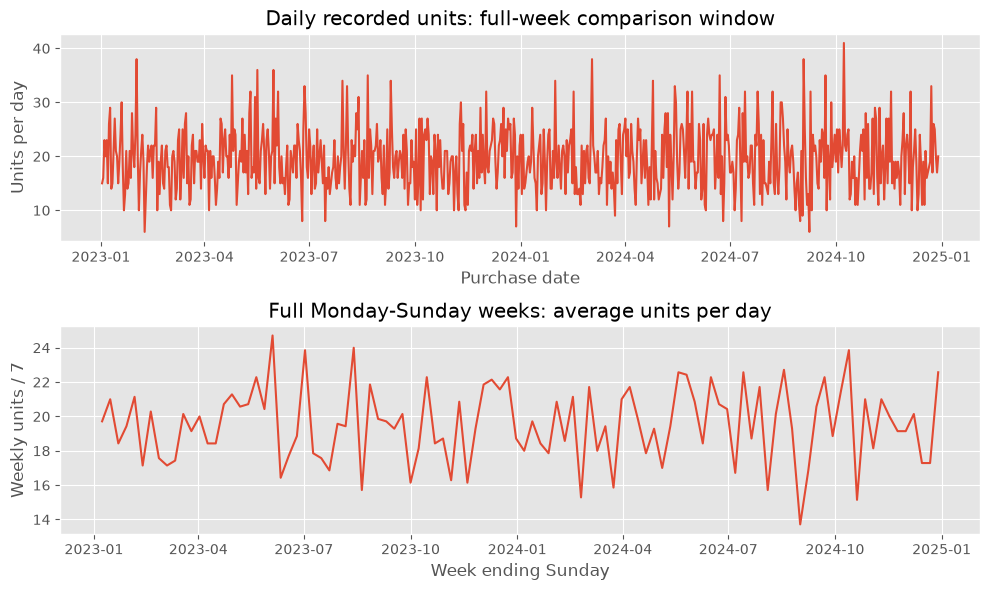

In [142]:
# Plotting daily units & the average units per day for each week.
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
sns.lineplot(data=comparison_days,x="purchase_date", y="units")
plt.title("Daily recorded units: full-week comparison window")
plt.xlabel("Purchase date")
plt.ylabel("Units per day")

plt.subplot(2, 1, 2)
sns.lineplot(data=full_weeks,x="week_end", y="units_per_day")
plt.title("Full Monday-Sunday weeks: average units per day")
plt.xlabel("Week ending Sunday")
plt.ylabel("Weekly units / 7")
plt.tight_layout()
plt.show()

### TIME COVERAGE SUMMARY

> - Both the full dataset & online purchases have records for every date from 1 January 2023 to 30 December 2024. No dates are missing within this period.
> - There are 104 weeks with records for all seven days. The first & last weeks contain only one recorded day each, so we left them out when comparing daily & weekly averages.
> - December 2024 has records for 30 days because the data ends on 30 December. The other 23 months have records for every day.
> - Using the same dates, both daily & weekly calculations give averages of about 20 units & 14 transactions per day. Weekly averages combine seven days, so they hide changes between individual days.

# TREND, VARIABILITY & CALENDAR PATTERNS

> - We'll look at daily & weekly changes & summarize the recent average & spread.
> - We'll compare weekdays, weekends & months using average activity per day.
> - We'll compare 2023 & 2024 using all observed days, noting that December 2024 covers 1–30 December.

In [143]:
# Preparing daily calendar columns & trailing rolling summaries.
daily_patterns = daily_summary.sort_values("purchase_date").copy()
daily_patterns = daily_patterns.reset_index(drop=True)
daily_patterns["year"] = daily_patterns["purchase_date"].dt.year
daily_patterns["month"] = daily_patterns["purchase_date"].dt.month
daily_patterns["weekday"] = daily_patterns["purchase_date"].dt.day_name()
daily_patterns["is_weekend"] = daily_patterns["purchase_date"].dt.dayofweek >= 5

daily_patterns["units_mean_7"] = daily_patterns["units"].rolling(7, min_periods=7).mean()
daily_patterns["units_mean_28"] = daily_patterns["units"].rolling(28, min_periods=28).mean()
daily_patterns["units_std_28"] = daily_patterns["units"].rolling(28, min_periods=28).std()

print(f"Total Day rows: {len(daily_patterns)}")
display(daily_patterns.tail(5))

Total Day rows: 730


,purchase_date,units,transactions,customers,recorded_amount,year,month,weekday,is_weekend,units_mean_7,units_mean_28,units_std_28
725,2024-12-26,25,15,15,140252,2024,12,Thursday,False,22.142857,19.535714,6.167310
726,2024-12-27,20,13,13,129572,2024,12,Friday,False,22.571429,19.250000,5.941848
727,2024-12-28,17,14,14,127523,2024,12,Saturday,True,22.428571,19.392857,5.833107
728,2024-12-29,20,16,16,75501,2024,12,Sunday,True,22.571429,19.321429,5.812207
729,2024-12-30,18,15,15,65984,2024,12,Monday,False,20.428571,19.107143,5.743526


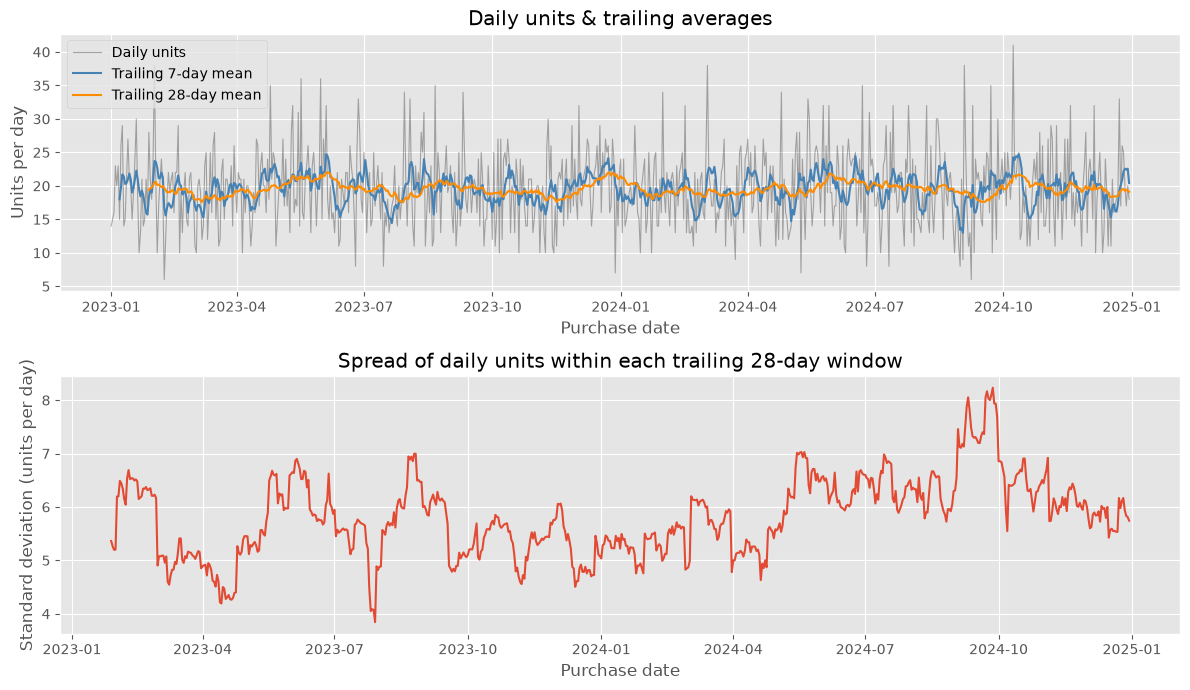

In [144]:
# Plotting daily units, recent averages & recent spread.
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
sns.lineplot(data=daily_patterns, x="purchase_date", y="units",
color="black", alpha=0.3, linewidth=0.8,label="Daily units")
sns.lineplot(data=daily_patterns, x="purchase_date", y="units_mean_7",
color="steelblue", label="Trailing 7-day mean")
sns.lineplot(data=daily_patterns, x="purchase_date", y="units_mean_28",
color="darkorange", label="Trailing 28-day mean")
plt.title("Daily units & trailing averages")
plt.xlabel("Purchase date")
plt.ylabel("Units per day")
plt.legend()

plt.subplot(2, 1, 2)
sns.lineplot(data=daily_patterns, x="purchase_date", y="units_std_28")
plt.title("Spread of daily units within each trailing 28-day window")
plt.xlabel("Purchase date")
plt.ylabel("Standard deviation (units per day)")

plt.tight_layout()
plt.show()

In [145]:
# Comparing average activity per day across weekdays & weekends.
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday_summary = daily_patterns.groupby("weekday").agg(
    days=("purchase_date", "count"),
    mean_units=("units", "mean"),
    mean_transactions=("transactions", "mean")).reindex(weekday_order).reset_index()

weekend_summary = daily_patterns.groupby("is_weekend").agg(
    days=("purchase_date", "count"),
    mean_units=("units", "mean"),
    mean_transactions=("transactions", "mean")).reset_index()

print(f"Average activity per day for each weekday")
display(weekday_summary.round(2))
print(f"Weekend comparison: False = Monday-Friday; True = Saturday-Sunday")
display(weekend_summary.round(2))

Average activity per day for each weekday


,weekday,days,mean_units,mean_transactions
0,Monday,105,19.46,13.79
1,Tuesday,104,18.87,13.21
2,Wednesday,104,20.46,14.24
3,Thursday,104,19.92,13.83
4,Friday,104,19.51,13.45
5,Saturday,104,19.12,13.70
6,Sunday,105,19.39,13.67


Weekend comparison: False = Monday-Friday; True = Saturday-Sunday


,is_weekend,days,mean_units,mean_transactions
0,False,521,19.64,13.70
1,True,209,19.26,13.68


In [146]:
# Summarizing monthly activity per recorded calendar day.
monthly_patterns = daily_patterns.groupby(pd.Grouper(
    key="purchase_date", freq="MS")).agg(
    mean_units=("units", "mean"),
    mean_transactions=("transactions", "mean")
).reset_index().rename(columns={"purchase_date": "month_start"})

monthly_patterns = monthly_patterns.merge(monthly_coverage[["month_start", 
"dates_with_records","days_in_month", "full_month"]],on="month_start", how="left")
monthly_patterns = monthly_patterns.sort_values("month_start").reset_index(drop=True)
monthly_patterns["year"] = monthly_patterns["month_start"].dt.year
monthly_patterns["month"] = monthly_patterns["month_start"].dt.month

display(monthly_patterns.round(2))

,month_start,mean_units,mean_transactions,dates_with_records,days_in_month,full_month,year,month
0,2023-01-01,19.55,13.81,31,31,True,2023,1
1,2023-02-01,18.96,13.68,28,28,True,2023,2
2,2023-03-01,18.68,13.48,31,31,True,2023,3
3,2023-04-01,19.67,13.80,30,30,True,2023,4
4,2023-05-01,21.45,15.29,31,31,True,2023,5
5,2023-06-01,19.57,13.43,30,30,True,2023,6
6,2023-07-01,18.42,13.00,31,31,True,2023,7
7,2023-08-01,20.42,14.03,31,31,True,2023,8
8,2023-09-01,18.90,13.30,30,30,True,2023,9
9,2023-10-01,18.81,13.61,31,31,True,2023,10


In [147]:
monthly_patterns.head(5).round(2)

,month_start,mean_units,mean_transactions,dates_with_records,days_in_month,full_month,year,month
0,2023-01-01,19.55,13.81,31,31,True,2023,1
1,2023-02-01,18.96,13.68,28,28,True,2023,2
2,2023-03-01,18.68,13.48,31,31,True,2023,3
3,2023-04-01,19.67,13.80,30,30,True,2023,4
4,2023-05-01,21.45,15.29,31,31,True,2023,5


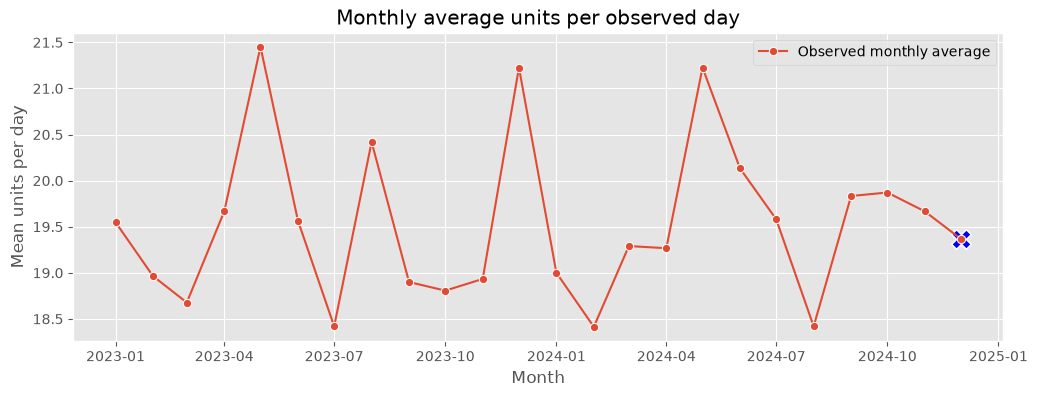

In [148]:
# Plotting monthly daily averages & marking the partial month.
partial_months = monthly_patterns[~monthly_patterns["full_month"]].copy()

plt.figure(figsize=(12, 4))
sns.lineplot(data=monthly_patterns, x="month_start", y="mean_units",
marker="o",label="Observed monthly average")
sns.scatterplot(data=partial_months, x="month_start", y="mean_units",marker="X",color="b",s=200)
plt.title("Monthly average units per observed day")
plt.xlabel("Month")
plt.ylabel("Mean units per day")
plt.legend()
plt.show()

In [149]:
# Comparing all observed days; 2024 data ends on 30 December.
comparison_period = daily_patterns.copy()
year_comparison = comparison_period.groupby("year").agg(
    days=("purchase_date", "count"),
    mean_units=("units", "mean"),
    mean_transactions=("transactions", "mean")).reset_index()

display(year_comparison.round(2))

,year,days,mean_units,mean_transactions
0,2023,365,19.56,13.77
1,2024,365,19.51,13.63


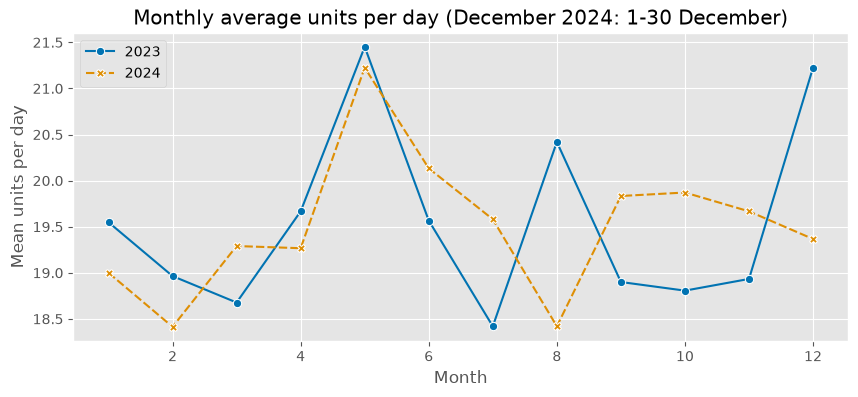

In [150]:
# Comparing monthly daily averages, including partial December 2024.
plt.figure(figsize=(10, 4))

sns.lineplot(data=monthly_patterns, x="month", y="mean_units",
hue="year", style="year", markers=True, palette="colorblind")

plt.title("Monthly average units per day (December 2024: 1-30 December)")
plt.xlabel("Month")
plt.ylabel("Mean units per day")
plt.legend()
plt.show()

### TREND & CALENDAR PATTERNS SUMMARY

> - Daily units fluctuate around 20 without a clear sustained rise or fall. Daily unit counts show larger fluctuations around September 2024.
> - Weekday & weekend activity is similar, averaging 19.64 & 19.26 units per day, with almost equal average transaction counts.
> - May has the highest monthly average units per day in both years, but other monthly patterns differ. Two years of data are not enough to establish firm annual seasonality.
> - Average daily units are similar in 2023 & 2024: 19.56 & 19.51 respectively. This comparison includes all observed days, with December 2024 covering only 1–30 December.

# TIME & BUSINESS-FACTOR PATTERNS

> - We'll compare how purchased units & transaction counts change across categories & channels over time.
> - We'll look at changes in product mix, sale labels & discounts.

In [151]:
# Preparing monthly totals for the business comparisons.
monthly_business = eda_df.groupby(pd.Grouper(
    key="purchase_date", freq="MS")).agg(
    total_units=("quantity", "sum"),
    total_transactions=("transaction_id", "nunique"),
    sale_transactions=("is_sale", "sum"),
    mean_discount=("discount", "mean"),
    total_sales=("purchase_amount","sum")
).reset_index().rename(columns={"purchase_date": "month_start"})

monthly_business = monthly_business.merge(
    monthly_patterns[["month_start", "dates_with_records", "full_month"]],
    on="month_start", how="left")

monthly_business["sale_transaction_pct"] = (
monthly_business["sale_transactions"] / monthly_business["total_transactions"] * 100)

display(monthly_business.head(5).round(2))
display(monthly_business.tail(5).round(2))

,month_start,total_units,total_transactions,sale_transactions,mean_discount,total_sales,dates_with_records,full_month,sale_transaction_pct
0,2023-01-01,606,428,147,11.77,2496771,31,True,34.35
1,2023-02-01,531,383,0,6.35,2248695,28,True,0.00
2,2023-03-01,579,418,0,6.76,2837727,31,True,0.00
3,2023-04-01,590,414,0,6.96,2543377,30,True,0.00
4,2023-05-01,665,474,0,6.85,2881711,31,True,0.00


,month_start,total_units,total_transactions,sale_transactions,mean_discount,total_sales,dates_with_records,full_month,sale_transaction_pct
19,2024-08-01,571,401,128,11.62,2366289,31,True,31.92
20,2024-09-01,595,412,14,7.77,3189510,30,True,3.40
21,2024-10-01,616,424,144,13.09,2718720,31,True,33.96
22,2024-11-01,590,410,141,12.76,2812852,30,True,34.39
23,2024-12-01,581,417,4,7.14,2681610,30,False,0.96


,month_start,category,units,transactions,total_units,dates_with_records,units_per_day,transactions_per_day,unit_share_pct
0,2023-01-01,Accessories,83,60,606,31,2.68,1.94,13.70
1,2023-01-01,Clothing,326,225,606,31,10.52,7.26,53.80
2,2023-01-01,Footwear,197,143,606,31,6.35,4.61,32.51
3,2023-02-01,Accessories,106,75,531,28,3.79,2.68,19.96
4,2023-02-01,Clothing,245,175,531,28,8.75,6.25,46.14
...,...,...,...,...,...,...,...,...,...
67,2024-11-01,Clothing,293,208,590,30,9.77,6.93,49.66
68,2024-11-01,Footwear,205,143,590,30,6.83,4.77,34.75
69,2024-12-01,Accessories,107,71,581,30,3.57,2.37,18.42
70,2024-12-01,Clothing,270,194,581,30,9.00,6.47,46.47


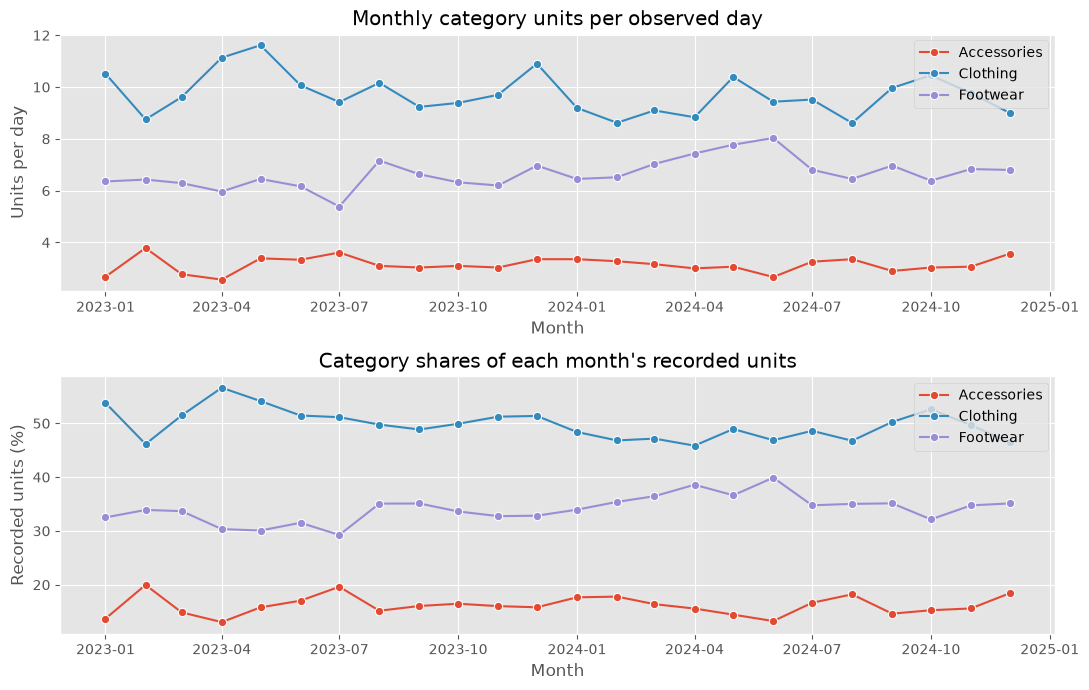

In [152]:
# Comparing monthly category activity & each category's unit share.
category_monthly = eda_df.groupby([pd.Grouper(key="purchase_date", freq="MS"), "category"]).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique")
).reset_index().rename(columns={"purchase_date": "month_start"})

category_monthly = category_monthly.merge(
    monthly_business[["month_start", "total_units", "dates_with_records"]],
    on="month_start", how="left")

category_monthly["units_per_day"] = (
    category_monthly["units"] / category_monthly["dates_with_records"])
category_monthly["transactions_per_day"] = (
    category_monthly["transactions"] / category_monthly["dates_with_records"])
category_monthly["unit_share_pct"] = (
    category_monthly["units"] / category_monthly["total_units"] * 100)

display(category_monthly.round(2))

plt.figure(figsize=(11, 7))

plt.subplot(2, 1, 1)
sns.lineplot(data=category_monthly, x="month_start", y="units_per_day",
hue="category", marker="o")
plt.title("Monthly category units per observed day")
plt.xlabel("Month")
plt.ylabel("Units per day")
plt.legend()

plt.subplot(2, 1, 2)
sns.lineplot(data=category_monthly, x="month_start", y="unit_share_pct",
hue="category", marker="o")
plt.title("Category shares of each month's recorded units")
plt.xlabel("Month")
plt.ylabel("Recorded units (%)")
plt.legend()

plt.tight_layout()
plt.show()

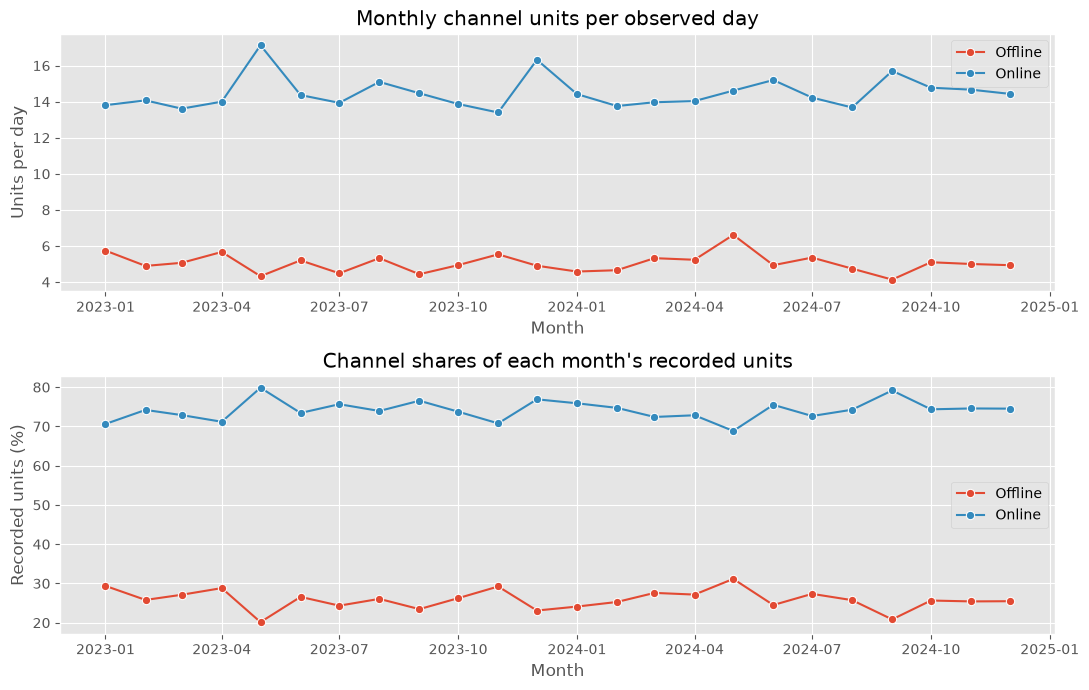

,month_start,online/offline,units,transactions,total_units,dates_with_records,units_per_day,transactions_per_day,unit_share_pct
0,2023-01-01,Offline,178,128,606,31,5.74,4.13,29.37
1,2023-01-01,Online,428,300,606,31,13.81,9.68,70.63
2,2023-02-01,Offline,137,100,531,28,4.89,3.57,25.80
3,2023-02-01,Online,394,283,531,28,14.07,10.11,74.20
4,2023-03-01,Offline,157,114,579,31,5.06,3.68,27.12
5,2023-03-01,Online,422,304,579,31,13.61,9.81,72.88
6,2023-04-01,Offline,170,122,590,30,5.67,4.07,28.81
7,2023-04-01,Online,420,292,590,30,14.00,9.73,71.19
8,2023-05-01,Offline,134,95,665,31,4.32,3.06,20.15
9,2023-05-01,Online,531,379,665,31,17.13,12.23,79.85


In [153]:
# Comparing monthly online & offline activity.
channel_monthly = eda_df.groupby([pd.Grouper(key="purchase_date", freq="MS"), "online/offline"]).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "nunique")
).reset_index().rename(columns={"purchase_date": "month_start"})

channel_monthly = channel_monthly.merge(monthly_business[[
"month_start", "total_units", "dates_with_records"]],on="month_start", how="left")

channel_monthly["units_per_day"] = (
    channel_monthly["units"] / channel_monthly["dates_with_records"])
channel_monthly["transactions_per_day"] = (
    channel_monthly["transactions"] / channel_monthly["dates_with_records"])
channel_monthly["unit_share_pct"] = (
    channel_monthly["units"] / channel_monthly["total_units"] * 100)

plt.figure(figsize=(11, 7))

plt.subplot(2, 1, 1)
sns.lineplot(data=channel_monthly, x="month_start", y="units_per_day",
hue="online/offline", marker="o")
plt.title("Monthly channel units per observed day")
plt.xlabel("Month")
plt.ylabel("Units per day")
plt.legend()

plt.subplot(2, 1, 2)
sns.lineplot(data=channel_monthly, x="month_start", y="unit_share_pct",
hue="online/offline", marker="o")
plt.title("Channel shares of each month's recorded units")
plt.xlabel("Month")
plt.ylabel("Recorded units (%)")
plt.legend()

plt.tight_layout()
plt.show()
display(channel_monthly.round(2))

In [154]:
# Comparing each item's share of recorded units in 2023 & 2024.
item_year = eda_df.groupby(["year", "item_purchased"]).agg(units=("quantity", "sum"),
transactions=("transaction_id", "nunique")).reset_index()

year_unit_totals = eda_df.groupby("year")["quantity"].sum()
item_year["unit_share_pct"] = (item_year["units"] / item_year["year"].map(year_unit_totals) * 100)

item_share_comparison = item_year.pivot(
index="item_purchased", columns="year", values="unit_share_pct").reset_index()

display(year_unit_totals.reset_index(name="recorded_units"))
display(item_share_comparison.round(2))

,year,recorded_units
0,2023,7138
1,2024,7121


year,item_purchased,2023,2024
0,Backpack,2.66,2.51
1,Bag,2.30,2.61
2,Belt,2.06,2.20
3,Boots,2.84,3.67
4,Cap,1.99,1.95
5,Dress,1.98,2.64
6,Formal Shoes,3.42,3.50
7,Heels,3.50,3.54
8,Hoodie,4.30,4.03
9,Jacket,6.99,6.56


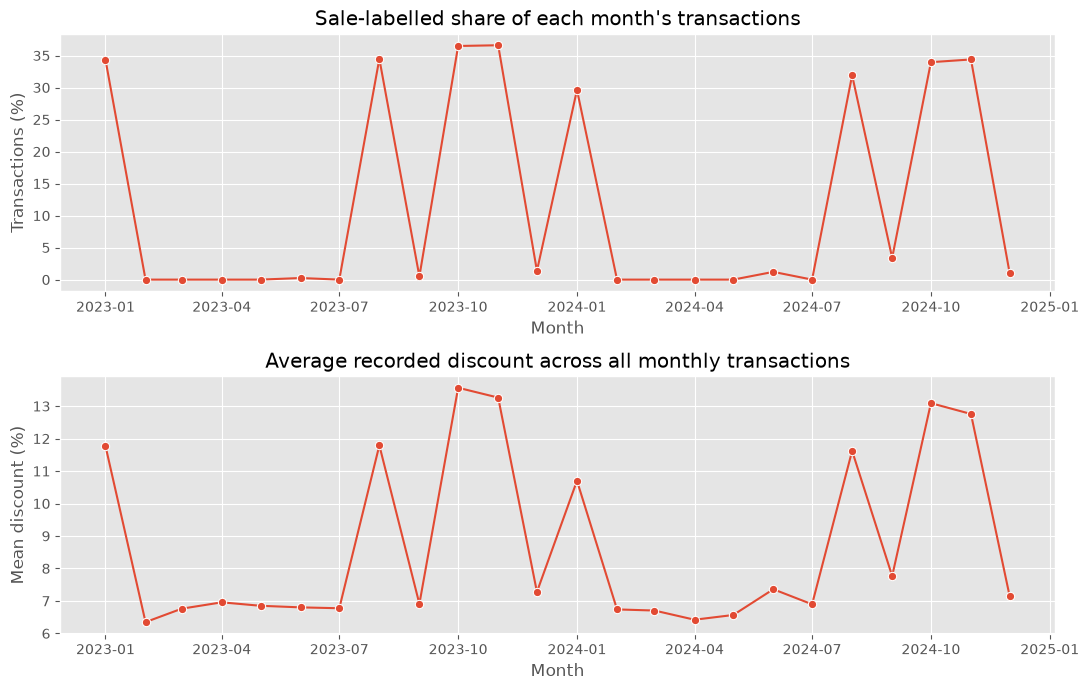

In [155]:
# Comparing monthly sale-labelled transactions & average discounts.
plt.figure(figsize=(11, 7))

plt.subplot(2, 1, 1)
sns.lineplot(data=monthly_business, x="month_start", y="sale_transaction_pct",marker="o")
plt.title("Sale-labelled share of each month's transactions")
plt.xlabel("Month")
plt.ylabel("Transactions (%)")

plt.subplot(2, 1, 2)
sns.lineplot(data=monthly_business, x="month_start", y="mean_discount",marker="o")
plt.title("Average recorded discount across all monthly transactions")
plt.xlabel("Month")
plt.ylabel("Mean discount (%)")

plt.tight_layout()
plt.show()

In [156]:
# Checking recorded dates & transaction counts for each sale label.
event_timing = eda_df[eda_df["is_sale"]].groupby("festival/sale").agg(
    transactions=("transaction_id", "nunique"),
    dates_with_records=("purchase_date", "nunique"),
    first_record=("purchase_date", "min"),
    last_record=("purchase_date", "max"),
    mean_discount=("discount", "mean")).reset_index()

display(event_timing.round(2))

,festival/sale,transactions,dates_with_records,first_record,last_record,mean_discount
0,Amazon Great Indian Festival,16,13,2023-10-01,2024-10-25,39.62
1,Big Billion Days,19,19,2023-09-10,2024-10-27,41.58
2,Diwali Sale,124,80,2023-10-02,2024-11-29,32.89
3,In-Store Festival Offer,878,237,2023-01-01,2024-11-30,19.40
4,Independence Day Sale,62,39,2023-08-02,2024-08-30,24.34
5,Myntra End of Reason Sale,16,14,2023-06-23,2024-12-15,45.56
6,Nykaa Pink Friday,10,9,2023-11-13,2024-11-30,37.70
7,Republic Day Sale,40,28,2023-01-02,2024-01-28,25.12


### TIME & BUSINESS-FACTOR PATTERNS SUMMARY

> - Clothing contributes the most units every month, accounting for about 46–57% of monthly units. Online purchases also lead throughout, contributing about 69–80%.
> - Product shares change between years. Running Shoes increase from 7.83% of recorded units in 2023 to 9.18% in 2024, while Kurta decreases from 9.46% to 8.07%.
> - January, August, October & November have higher shares of sale-labelled transactions & higher average discounts in both years. However, May has the highest average daily units in both years despite having no sale-labelled transactions.
> - Some event labels contain only 10–19 transactions.

# COMPARING CURRENT & PAST PURCHASES

> - We'll compare daily & weekly purchased units with totals from earlier days & weeks.
> - We'll check whether the daily relationships look similar in 2023 & 2024.

In [157]:
# Comparing daily & weekly units with earlier totals.
daily_units = daily_summary.set_index("purchase_date")["units"]
daily_units = daily_units.sort_index()
weekly_units = full_weeks.set_index("week_end")["units"]
weekly_units = weekly_units.sort_index()

daily_relationships = pd.DataFrame({
    "days_earlier": [1, 7, 14],
    "correlation": [
    daily_units.autocorr(lag=1),
    daily_units.autocorr(lag=7),
    daily_units.autocorr(lag=14)]})

weekly_relationships = pd.DataFrame({
    "weeks_earlier": [1, 4],
    "correlation": [weekly_units.autocorr(lag=1),weekly_units.autocorr(lag=4)]})

print(f"Days available: {len(daily_units)}")
display(daily_relationships.round(3))
print(f"Complete weeks available: {len(weekly_units)}")
display(weekly_relationships.round(3))

Days available: 730


,days_earlier,correlation
0,1,-0.016
1,7,-0.080
2,14,-0.034


Complete weeks available: 104


,weeks_earlier,correlation
0,1,-0.126
1,4,0.193


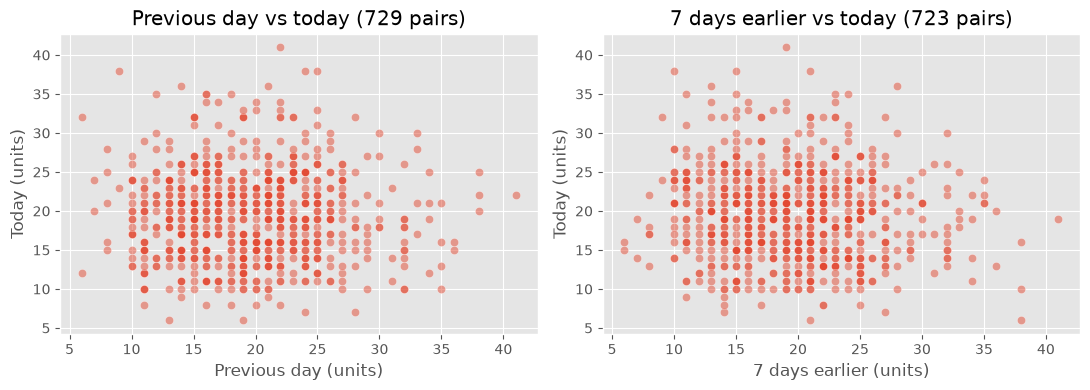

In [158]:
# Plotting today's units against earlier daily units.
previous_day_pairs = pd.DataFrame({
    "previous_day": daily_units.shift(1),
    "today": daily_units}).dropna()

seven_day_pairs = pd.DataFrame({
    "seven_days_earlier": daily_units.shift(7),
    "today": daily_units}).dropna()

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
sns.scatterplot(data=previous_day_pairs,x="previous_day", y="today", alpha=0.5)
plt.title(f"Previous day vs today ({len(previous_day_pairs)} pairs)")
plt.xlabel("Previous day (units)")
plt.ylabel("Today (units)")

plt.subplot(1, 2, 2)
sns.scatterplot(data=seven_day_pairs,x="seven_days_earlier", y="today", alpha=0.5)
plt.title(f"7 days earlier vs today ({len(seven_day_pairs)} pairs)")
plt.xlabel("7 days earlier (units)")
plt.ylabel("Today (units)")

plt.tight_layout()
plt.show()

In [159]:
# Repeating the daily comparisons for 2023 & 2024.
daily_units_2023 = daily_units.loc["2023"]
daily_units_2024 = daily_units.loc["2024"]

year_relationships = pd.DataFrame({"days_earlier": [1, 7, 14],
"2023": [daily_units_2023.autocorr(lag=1),daily_units_2023.autocorr(lag=7),
daily_units_2023.autocorr(lag=14)],
"2024": [daily_units_2024.autocorr(lag=1),daily_units_2024.autocorr(lag=7),
daily_units_2024.autocorr(lag=14)]})

print(f"Days available: 2023 = {len(daily_units_2023)}; 2024 = {len(daily_units_2024)}")
display(year_relationships.round(3))

Days available: 2023 = 365; 2024 = 365


,days_earlier,2023,2024
0,1,0.006,-0.036
1,7,-0.103,-0.066
2,14,0.020,-0.060


### CURRENT & PAST PURCHASES SUMMARY

> - Daily purchased units have very weak relationships with units 1, 7 & 14 days earlier. The scatterplots also show no clear upward or downward pattern.
> - Weekly totals show weak relationships with totals 1 & 4 weeks earlier. The four-week relationship is slightly positive, but this alone is not enough to identify a repeating monthly pattern.
> - Daily relationships remain weak in both 2023 & 2024. These comparisons provide little evidence of a clear weekly repeat in daily purchased units.

# HIGH & LOW PURCHASE PERIODS

> - We'll compare the highest & lowest purchased-unit weeks with records on all seven dates.
> - We'll inspect their categories, channels, transaction sizes, sale labels & discounts.

,period,index,week_end,units,transactions,customers,recorded_amount,dates_with_records,week_start,full_week,units_per_day,transactions_per_day
0,Highest-unit week,22,2023-06-04,173,119,117,704018,7,2023-05-29,True,24.714286,17.000000
1,Lowest-unit week,87,2024-09-01,96,68,68,498777,7,2024-08-26,True,13.714286,9.714286


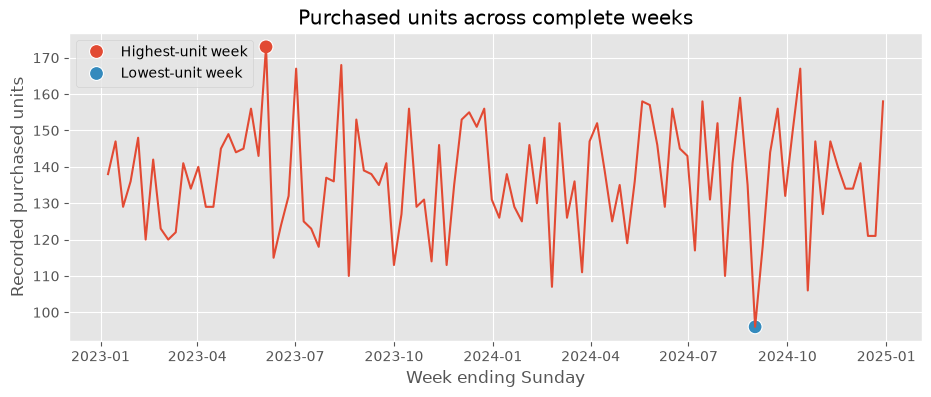

In [160]:
# Selecting the highest & lowest complete weeks by purchased units.
highest_week = full_weeks.loc[full_weeks["units"].idxmax()]
lowest_week = full_weeks.loc[full_weeks["units"].idxmin()]

selected_weeks = pd.DataFrame([highest_week, lowest_week]).reset_index()
selected_weeks.insert(0, "period",["Highest-unit week", "Lowest-unit week"])

display(selected_weeks)

plt.figure(figsize=(11, 4))
sns.lineplot(data=full_weeks, x="week_end", y="units")
sns.scatterplot(data=selected_weeks, x="week_end", y="units",hue="period",s=100)
plt.title("Purchased units across complete weeks")
plt.xlabel("Week ending Sunday")
plt.ylabel("Recorded purchased units")
plt.legend()
plt.show()

In [161]:
# Comparing category & channel contributions in the selected weeks.
high_purchases = eda_df[eda_df["purchase_date"].between(
highest_week["week_start"], highest_week["week_end"])].copy()
high_purchases["period"] = "Highest-unit week"

low_purchases = eda_df[eda_df["purchase_date"].between(
lowest_week["week_start"], lowest_week["week_end"])].copy()
low_purchases["period"] = "Lowest-unit week"

period_purchases = pd.concat([high_purchases, low_purchases], ignore_index=True)
period_unit_totals = selected_weeks.set_index("period")["units"]

category_contribution = period_purchases.groupby(["period", "category"]).agg(
units=("quantity", "sum"),transactions=("transaction_id", "nunique")).reset_index()
category_contribution["unit_share_pct"] = (category_contribution["units"]
/ category_contribution["period"].map(period_unit_totals) * 100)

channel_contribution = period_purchases.groupby(["period", "online/offline"]).agg(
units=("quantity", "sum"),transactions=("transaction_id", "nunique")).reset_index()
channel_contribution["unit_share_pct"] = (channel_contribution["units"]
/ channel_contribution["period"].map(period_unit_totals) * 100)

print(f"Category contributions:")
display(category_contribution.round(2))
print(f"Channel contributions:")
display(channel_contribution.round(2))

Category contributions:


,period,category,units,transactions,unit_share_pct
0,Highest-unit week,Accessories,42,26,24.28
1,Highest-unit week,Clothing,87,61,50.29
2,Highest-unit week,Footwear,44,32,25.43
3,Lowest-unit week,Accessories,24,16,25.00
4,Lowest-unit week,Clothing,45,34,46.88
5,Lowest-unit week,Footwear,27,18,28.12


Channel contributions:


,period,online/offline,units,transactions,unit_share_pct
0,Highest-unit week,Offline,38,27,21.97
1,Highest-unit week,Online,135,92,78.03
2,Lowest-unit week,Offline,18,15,18.75
3,Lowest-unit week,Online,78,53,81.25


In [162]:
# Comparing transaction sizes, sale labels & discounts.
week_context = period_purchases.groupby("period").agg(
    transactions=("transaction_id", "nunique"),
    sale_transactions=("is_sale", "sum"),
    mean_units_per_transaction=("quantity", "mean"),
    mean_discount=("discount", "mean"),
    median_discount=("discount", "median")).reset_index()

week_context["sale_transaction_pct"] = (week_context["sale_transactions"]
/ week_context["transactions"] * 100)

label_counts = period_purchases.groupby(["period", "festival/sale"]).agg(
transactions=("transaction_id", "nunique")).reset_index()

print(f"Transaction sizes, sale shares & discounts:")
display(week_context.round(2))
print(f"Recorded transaction labels:")
display(label_counts)

Transaction sizes, sale shares & discounts:


,period,transactions,sale_transactions,mean_units_per_transaction,mean_discount,median_discount,sale_transaction_pct
0,Highest-unit week,119,0,1.45,6.14,6.0,0.0
1,Lowest-unit week,68,17,1.41,11.49,10.0,25.0


Recorded transaction labels:


,period,festival/sale,transactions
0,Highest-unit week,Standard Day,119
1,Lowest-unit week,In-Store Festival Offer,12
2,Lowest-unit week,Independence Day Sale,5
3,Lowest-unit week,Standard Day,51


### HIGH & LOW PURCHASE PERIODS SUMMARY

> - Among the 104 complete weeks, purchased units are highest during 29 May–4 June 2023 (173 units) & lowest during 26 August–1 September 2024 (96 units). These extremes alone do not establish data errors or a lasting change.
> - The higher total mainly reflects more transactions (119 vs 68), while average units per transaction are similar (1.45 vs 1.41).
> - The lowest week has fewer units across all three categories & both channels. Clothing remains the largest category in both weeks (about 47–50% of units), while online purchases contribute about 78–81%.
> - The lowest week has a higher sale-labelled transaction share (25% vs 0%) & mean discount (11.49% vs 6.14%). Higher discounts & more sale labels do not accompany the higher weekly total here; this comparison cannot establish a causal promotion effect.

# FINAL EDA CONCLUSION

> - The dataset contains 10,000 transactions from 3,291 customers, covering every date from 1 January 2023 to 30 December 2024. No missing values or duplicate transaction IDs were found. Plausible extreme values were retained.
>
> - Online purchases contribute about 74% of recorded units, while Clothing contributes about half. Footwear has the highest typical purchase amount. Spending differences between categories are more noticeable than differences between channels.
>
> - Around 69% of transactions contain one unit. Purchase amounts are right-skewed, with a few large purchases pulling the mean above the median. Returned transactions account for 17.51% of records & remain included in purchase amounts, so recorded spending is not verified net revenue.
>
> - Although around 82% of customers have multiple observed transactions, the median is only three across the dataset period. Individual customer histories are therefore limited. Recorded purchase-frequency labels do not establish actual calendar purchase intervals.
>
> - Daily purchased units fluctuate around 20 without a clear sustained rise or fall. Weekday, weekend & yearly activity are similar, while the checked daily & weekly lag relationships are weak. May leads in both years, but roughly two years of data are insufficient to establish firm annual seasonality.
>
> - The highest-unit week mainly reflects more transactions, with similar units per transaction to the lowest week. The lowest week has higher discounts & more sale-labelled transactions. These comparisons do not establish a causal promotion effect.
>
> - These findings describe observed purchases, not verified unconstrained demand. Complete date coverage does not confirm complete transaction collection, & sale labels are not a verified promotion calendar. These limits matter when interpreting business patterns & future forecasts.
>
> - Feature engineering & modeling will follow in a separate notebook, where forecast performance will need to be tested.

In [168]:
# Saving the formatted DataFrame.
df.to_csv("../data/processed/cleaned_data.csv", index=False)